# [이론] 집단 비교 — TF-IDF와 가중 로그 오즈

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 집단마다 단어를 비교하는가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 비정형 데이터(자연어)</div>
<h1 style="color:#000000;margin:10px 0">집단 비교 — TF-IDF와 가중 로그 오즈</h1>
<div style="font-size:1.05em;color:#656565">별점 낮은 리뷰와 높은 리뷰, 20대와 60대 이상의 민원이 어떤 단어를 더 쓰는지 비교하고 그 차이 가운데 우연과 품목 구성으로 생긴 부분을 따로 확인합니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 별점 낮은 리뷰는 어떤 단어를 더 쓰는가 [필수]

별점 낮은 리뷰가 더 쓰는 단어를 보면 고객이 무엇에 불만인지 알 수 있습니다. 이렇게 한 집단이 다른 집단보다 더 자주 쓰는 단어를 **특징 단어(distinctive words)** 라고 합니다.

그런데 한쪽에 더 많이 나온 차이는 별점이 아니라 아래 두 가지로도 생깁니다.

- **우연**: 별점과 관계없이 리뷰를 무작위로 두 집단으로 나눠도, 단어마다 쓴 리뷰 수는 두 쪽이 조금씩 다릅니다.
- **구성 차이**: 두 집단의 품목 비중이 다른 것입니다. 한 집단에 식품 리뷰가 많으면 별점과 관계없이 「맛있다」도 많이 나옵니다.

> 별점 낮은 리뷰가 더 쓰는 단어 가운데, 우연이나 구성 차이로는 설명되지 않는 단어는 무엇인가?

결론은 세 가지입니다.

- 별점 1·2점 리뷰는 「없다 · 반품 · 불편 · 떨어지다」를 더 씁니다.
- 이 차이는 우연으로 보기 어렵습니다. 리뷰에는 품목 정보가 없어, 구성 차이는 품목이 있는 민원 자료로 따로 확인합니다.
- 20대 민원이 더 자주 쓰는 단어 1위는 「환불」(20대 28%, 60대 이상 11%)입니다. 쓴 민원 대부분이 비교한 품목 밖이라, 품목 구성 때문인지는 아직 판단할 수 없습니다.

**두 자료는 어떻게 생겼나요?**

리뷰는 네이버 쇼핑 리뷰 20만 건에서 무작위로 추출한 2만 건입니다. 별점 1·2점이 9,947건, 4·5점이 10,053건이고 3점 리뷰는 없습니다. 아래 표는 리뷰 원본 파일의 앞 세 건입니다.

| 별점 | 본문 |
|---:|---|
| 5 | 배공빠르고 굿 |
| 2 | 택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고 |
| 5 | 아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 엉성하긴 하지만 편하고 가성비 최고예요. |

<details class="lms-extra"><summary>더 깊이 — 리뷰 자료의 출처 · 별점 분포 · 본문 길이</summary>

리뷰는 bab2min/corpus 저장소의 `naver_shopping.txt` 파일입니다. 저장소 안내에는 「Public Domain」으로 표시되어 있지만, 원래 리뷰 글의 저작권은 분명하지 않습니다.

이 파일은 3점이 빠진 가공본으로, 20만 건 가운데 1·2점이 100,037건, 4·5점이 99,963건입니다. 표본 2만 건의 본문 글자 수 중앙값은 29자라, 한두 문장으로 된 리뷰가 대부분입니다.

</details>

리뷰에는 품목 정보가 없어, 구성 차이는 민원 제목 표본 2만 건으로 확인합니다. 그 가운데 20대 2,175건과 60대 이상 2,446건을 비교합니다(나머지는 다른 연령대). 아래 표는 그 가운데 세 건입니다.

| 사건제목 | 연령대 | 품목 |
|---|---|---|
| 헬스장 개인PT 계약 취소 원해 | 20 - 29세 | 헬스장 |
| 요가원 3개월 결제 후 2개월분 환불 요청 | 20 - 29세 | 스포츠시설이용 |
| 정수기 렌탈 취소 후 비용청구 반환 | 65 - 69세 | 정수기대여(렌트) |

60대 이상은 60～64세 · 65～69세 · 70～79세 · 80세 이상을 합친 집단입니다.

**문서 비율이 높은 단어만 비교하면 무엇이 보이나요?**

**문서 비율**은 리뷰 100건 가운데 그 단어가 나온 리뷰가 몇 건인지입니다. 별점 1·2점 리뷰 9,947건 가운데 「없다」가 나온 리뷰는 1,028건이라 10.33%, 100건 가운데 10건쯤입니다. 한 리뷰에 여러 번 나와도 한 건으로 칩니다.

리뷰는 명사와 용언(동사 · 형용사)을, 민원 제목은 명사만 집계합니다. 「없다」 · 「빠르다」처럼 별점에 따라 달라지는 말에 용언이 많기 때문입니다.

아래 그림은 두 별점 집단의 문서 비율 상위 15 입니다.

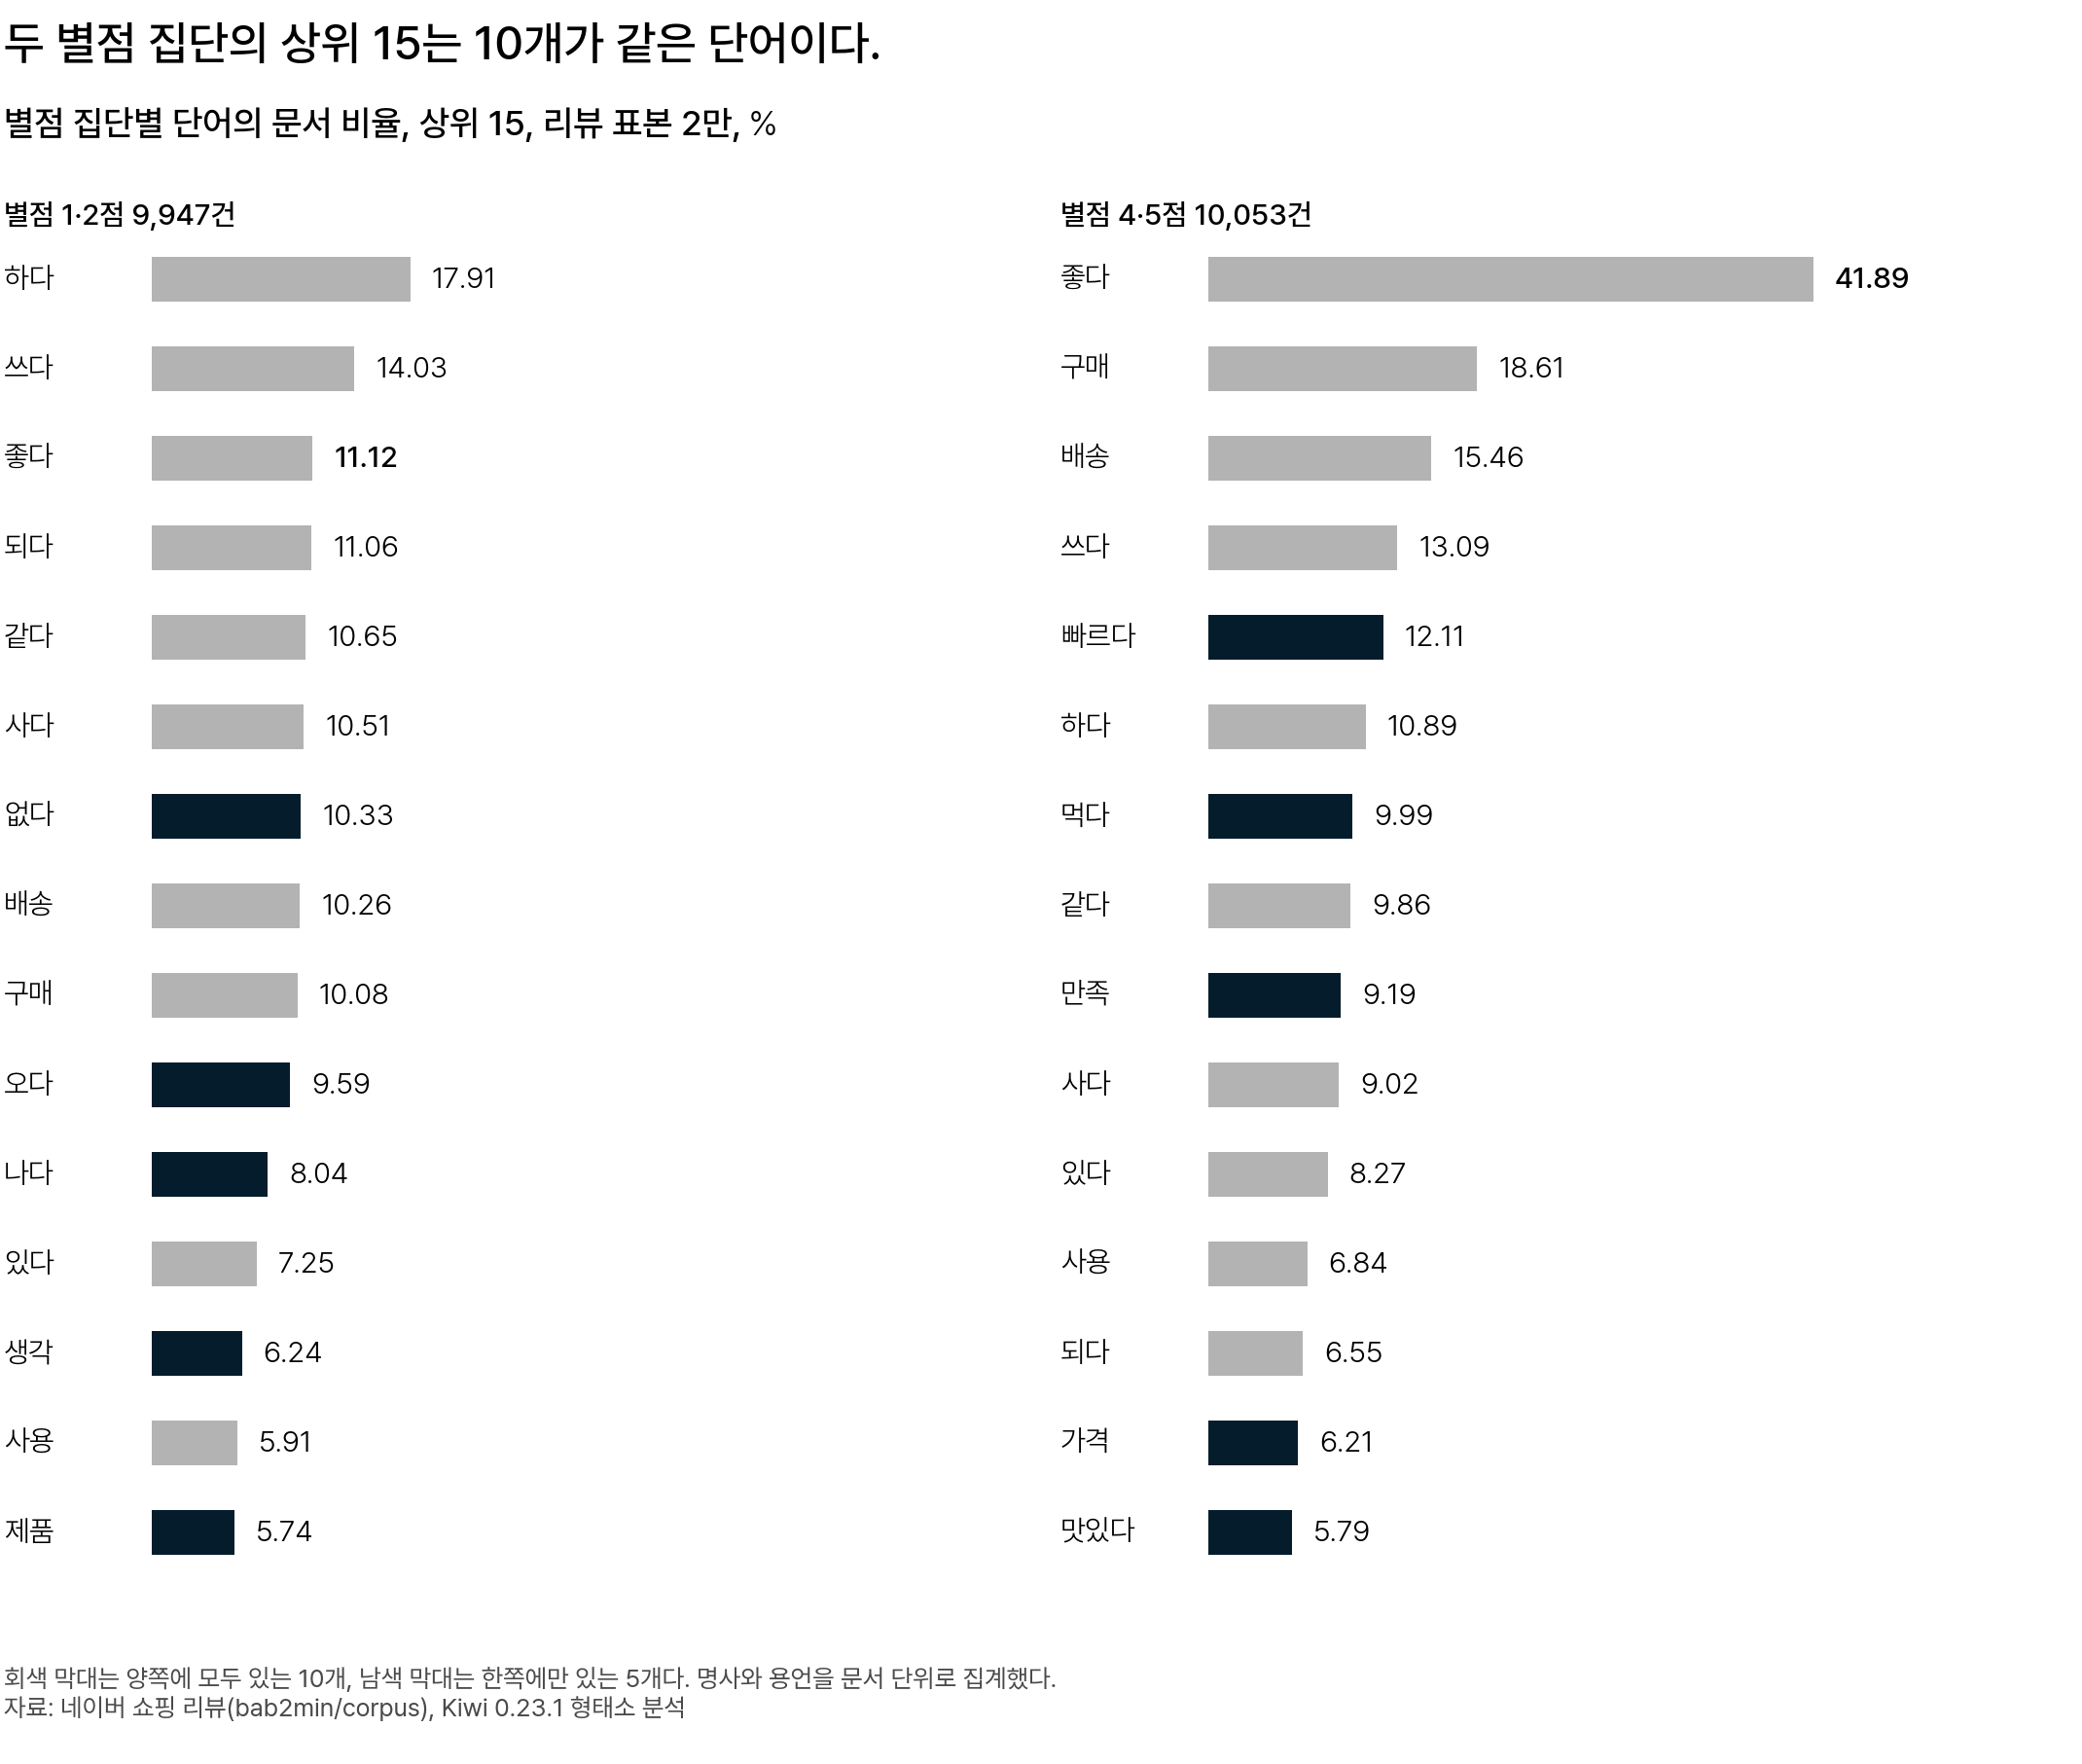

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 별점 집단별 문서 비율 상위 15. 막대 길이가 그 단어를 쓴 리뷰의 비율이다. 회색은 양쪽 상위 15 에 모두 있는 단어, 남색은 한쪽에만 있는 단어이고 두 쪽 막대는 같은 눈금이다</em></p>

양쪽 상위 15 에 모두 있는 단어는 「하다」 · 「쓰다」 · 「같다」처럼 별점과 상관없이 흔한 말입니다. 「쓰다」는 1·2점 쪽 14.03%, 4·5점 쪽 13.09% 로 비슷합니다.

한쪽 상위 15 에만 있는 단어는 쪽마다 5개입니다.

- 별점 1·2점 쪽: 없다 · 오다 · 나다 · 생각 · 제품
- 별점 4·5점 쪽: 빠르다 · 먹다 · 맛있다 · 만족 · 가격

상위 목록은 어느 리뷰에나 나오는 흔한 말이 양쪽을 차지합니다. 1·2점 쪽이 더 쓰는 「반품」 · 「불편」 같은 단어는 문서 비율이 낮아 상위 15 밖에 있습니다. 그래서 문서 비율 상위 목록으로는 특징 단어를 고르지 않고, 흔한 말의 점수를 낮추는 방법부터 봅니다.

<details class="lms-extra"><summary>더 깊이 — 흔한 말이 문서 비율 상위를 차지하는 이유</summary>

말뭉치마다 하다 · 쓰다처럼 어느 글에나 쓰이는 몇 안 되는 단어가 등장 횟수의 큰 비중을 차지합니다. 민원 제목 50만 건에서도 명사 30,798종 가운데 상위 100종이 명사가 나온 횟수 전체의 56.19% 를 차지합니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/a/ac/Zipf_30wiki_en_labels.png" alt="위키백과 30개 언어의 단어 순위와 등장 횟수" width="640" height="480" />
<p align="center"><em>▲ 문서 비율을 배울 때 본 지프 법칙 그림과 같은 자료다. 위키백과 30개 언어에서 단어를 많이 쓰인 순으로 나열한 순위(가로축 log(rank))와 등장 횟수(세로축 log(frecuency), 원문 철자 그대로). 언어마다 몇 안 되는 단어가 등장 횟수의 큰 비중을 차지한다 (출처: Wikimedia Commons, CC BY-SA 4.0)</em></p>

</details>

<div class="lms-summary">

**정리**

특징 단어는 한 집단이 더 자주 쓰는 단어이고, 그 차이는 우연과 구성 차이로도 생깁니다.

**할 일**

- 특징 단어 후보는 우연과 구성 차이로 생긴 차이인지 확인한 뒤에 씁니다

문서 비율 상위 목록은 흔한 말이 양쪽에 겹쳐 특징 단어를 고르는 데 쓰지 않습니다.

</div>

## 1. TF-IDF

「하다」 · 「쓰다」처럼 어느 리뷰에나 나오는 말은 점수를 낮추고 싶습니다. 이 문서에 여러 번 나오면서 다른 문서에는 드문 말은 점수를 높이려면 어떻게 할까요? 가장 널리 쓰는 방법이 TF-IDF 입니다. 이 점수를 두 집단 비교에 쓸 수 있는지는 「2. TF-IDF 로 두 집단을 비교할 때의 한계」에서 봅니다.

### TF-IDF 란 무엇인가 [필수]

**한 줄로 말하면 무엇인가요?**

**TF-IDF** 는 한 단어가 이 문서를 얼마나 잘 나타내는지 매기는 점수입니다. 반 친구 모두가 쓰는 「안녕」은 누구의 말버릇인지 알려 주지 못하듯, 모든 문서에 나오는 단어는 점수를 낮춥니다.

**TF 와 IDF 는 무엇인가요?**

tf 에 idf 를 곱한 값이 TF-IDF 입니다.

- **tf(term frequency)**: 한 문서의 단어 가운데 그 단어가 차지하는 비율입니다. 단어가 3개인 문서에 한 번 나오면 1/3 입니다.
- **idf(inverse document frequency)**: 그 단어가 나온 문서 수로 정하는 가중치입니다. 나온 문서가 적은 단어일수록 idf 가 큽니다.

| TF | IDF | TF-IDF | 뜻 |
|---|---|---|---|
| 높음 | 높음 | 높음 | 이 문서에 많이 나오고 다른 문서에는 적게 나오는 단어 |
| 높음 | 낮음 | 중간 | 이 문서에도 많고 다른 문서에도 많은 단어 |
| 낮음 | 높음 | 중간 | 이 문서에도 적고 다른 문서에도 적은 단어 |
| 낮음 | 낮음 | 낮음 | 이 문서에는 적고 다른 문서에는 많은 단어 |

그래서 이 문서에 많이 나오고 다른 문서에는 드문 단어가 그 문서의 중요 단어가 됩니다.

**어떤 순서로 계산하나요?**

- ① 어휘: 문서에 나온 단어를 모아 가나다순으로 번호를 정합니다. 단어를 가나다순으로 나열합니다(늦음 · 만족 · 배송 …).
- ② TF: 단어가 나온 횟수를 그 문서의 단어 수로 나눕니다.
- ③ IDF: 단어마다 나온 문서 수(df)로 idf 를 구합니다.
- ④ TF-IDF: 문서마다 tf 와 idf 를 곱합니다.

**예시 문서 세 개로 계산하면 어떻게 되나요?**

② TF 는 아래 식입니다.

$$
\mathrm{tf}(t, d) = \frac{\text{문서 } d \text{ 에서 단어 } t \text{ 가 나온 횟수}}{\text{문서 } d \text{ 의 전체 단어 수}}
$$

| 문서 | 단어 수 | 늦음 | 만족 | 배송 | 빠름 | 요청 | 환불 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1 「배송 빠름 만족」 | 3 | 0 | 1/3 | 1/3 | 1/3 | 0 | 0 |
| 2 「배송 늦음 환불」 | 3 | 1/3 | 0 | 1/3 | 0 | 0 | 1/3 |
| 3 「환불 요청 환불」 | 3 | 0 | 0 | 0 | 0 | 1/3 | 2/3 |

문서 1 「배송 빠름 만족」의 배송은 3개 가운데 1개라 1/3 = 0.333 입니다. 문서 3 「환불 요청 환불」은 환불 2개 + 요청 1개라 전체 단어 수가 3 이고, 환불은 2/3 = 0.667 입니다.

③ IDF 는 scikit-learn `TfidfVectorizer` 의 기본식으로 구합니다.

$$
\mathrm{idf}(t) = \ln\frac{1 + N}{1 + \mathrm{df}(t)} + 1
$$

- $N$: 전체 문서 수(예시는 3)
- $\mathrm{df}(t)$: 단어 $t$ 가 나온 문서 수
- $\ln$: 자연로그(`np.log`)입니다. 드문 단어와 흔한 단어의 idf 차이를 줄입니다. 문서 1만 건이면 로그 없이 약 2,500배, 로그를 쓰면 약 5.6배입니다
- 끝의 $+1$: 모든 문서에 나온 흔한 단어도 idf 가 0 이 되지 않게 합니다. 0 이면 그 단어가 문서에서 지워진 것과 같아, 점수를 조금은 남깁니다(idf 의 가장 작은 값이 1)
- 분자 · 분모의 $+1$: df 가 0 인 단어가 있어도 0 으로 나누지 않게 합니다. 모든 단어를 한 번씩 포함한 문서가 하나 더 있다고 치는 것이라 N 과 df 에 똑같이 1 을 더합니다

예시는 $N = 3$ 이라 분자가 언제나 1 + 3 = 4 입니다.

| 단어 | 나온 문서 | df | (1 + N) ÷ (1 + df) | ln(앞의 값) | idf = ln + 1 |
|---|---|---:|---:|---:|---:|
| 늦음 · 만족 · 빠름 · 요청 | 한 문서씩 | 1 | 4 ÷ 2 = 2 | 0.693 | 1.693 |
| 배송 · 환불 | 두 문서씩 | 2 | 4 ÷ 3 = 1.333 | 0.288 | 1.288 |

두 문서에 나온 배송 · 환불은 idf 가 1.288 로, 한 문서에만 나온 단어의 1.693 보다 작습니다.

<details class="lms-extra"><summary>자세히 — idf 식의 로그와 교과서식</summary>

문서 1만 건에서 한 문서에만 나온 단어와 5,000건에 나온 단어를 비교합니다.

| 단어가 나온 문서 수 df | 로그 없이 비 (1 + N) ÷ (1 + df) | 로그를 쓴 ln(비) + 1 |
|---:|---:|---:|
| 1 | 5,000.5 | 9.517 |
| 5,000 | 2.0 | 1.693 |
| 두 가중치의 배수 | 약 2,500배 | 약 5.6배 |

로그가 없으면 5,000건에 나온 단어는 한 문서에 2,501번 나와야 드문 단어 한 번의 값을 넘습니다. 로그를 쓰면 6번이면 넘습니다(6 × 1.693 = 10.2).

교과서는 흔히 $\mathrm{idf} = \ln(N/\mathrm{df})$ 를 씁니다. 이 식이면 문서 3 의 환불은 0.667 × 0.405 = 0.270, 요청은 0.333 × 1.099 = 0.366 입니다. scikit-learn 식에서는 환불(0.858)이 요청(0.564)보다 큰데, 교과서식에서는 요청이 더 큽니다.

</details>

④ TF-IDF 는 ② 의 tf 에 ③ 의 idf 를 곱합니다. 문서에 없는 단어는 tf 가 0 이라 TF-IDF 도 0 입니다.

| 문서 | 단어 | tf | idf | tf × idf |
|---|---|---:|---:|---:|
| 1 | 만족 | 1/3 | 1.693 | 0.333 × 1.693 = 0.564 |
| 1 | 빠름 | 1/3 | 1.693 | 0.333 × 1.693 = 0.564 |
| 1 | 배송 | 1/3 | 1.288 | 0.333 × 1.288 = 0.429 |
| 2 | 늦음 | 1/3 | 1.693 | 0.333 × 1.693 = 0.564 |
| 2 | 배송 | 1/3 | 1.288 | 0.333 × 1.288 = 0.429 |
| 2 | 환불 | 1/3 | 1.288 | 0.333 × 1.288 = 0.429 |
| 3 | 요청 | 1/3 | 1.693 | 0.333 × 1.693 = 0.564 |
| 3 | 환불 | 2/3 | 1.288 | 0.667 × 1.288 = 0.858 |

문서마다 값이 가장 큰 단어는 문서 1 만족 · 빠름, 문서 2 늦음, 문서 3 환불입니다. 문서 1 의 배송이 만족 · 빠름보다 낮은 것은 문서 2 에도 나와 문서 1 만의 단어가 아니기 때문입니다. 문서 3 의 환불은 idf 가 요청보다 작아도 두 번 나와 값이 더 큽니다.

아래 코드는 같은 계산을 numpy 로 합니다. 「정규화 전」 줄을 위 표의 문서 1 · 3 과 비교해 봅니다.

In [ ]:
# 예시 문서 세 개의 TF-IDF: 손계산(numpy)과 scikit-learn 기본값을 비교한다
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

docs = ["배송 빠름 만족", "배송 늦음 환불", "환불 요청 환불"]
vocab = ["늦음", "만족", "배송", "빠름", "요청", "환불"]        # 가나다순 어휘
count = np.array([[d.split().count(w) for w in vocab] for d in docs])   # 문서-단어 행렬(나온 횟수)
tf = count / count.sum(axis=1, keepdims=True)              # 횟수 ÷ 문서의 단어 수
N = len(docs)
df = (count > 0).sum(axis=0)                               # 단어마다 나온 문서 수
idf = np.log((1 + N) / (1 + df)) + 1                       # scikit-learn 기본식
raw = tf * idf                                             # 정규화 전 tf × idf
x = raw / np.sqrt((raw ** 2).sum(axis=1, keepdims=True))   # 문서마다 L2 정규화(아래 소제목)

print("idf:", {w: float(v) for w, v in zip(vocab, idf.round(3))})
print("정규화 전 문서 1:", raw[0].round(3), "· 문서 3:", raw[2].round(3))
print("정규화 뒤 문서 1:", x[0].round(3), "· 문서 3:", x[2].round(3))
sk = TfidfVectorizer(vocabulary=vocab).fit_transform(docs).toarray()
print("scikit-learn 과 같은가:", np.allclose(x, sk))

### L2 정규화 [필수]

**scikit-learn 은 왜 마지막에 한 번 더 나누나요?**

scikit-learn 은 tf 로 비율 대신 나온 횟수를 씁니다. 그러면 내용이 같아도 길이가 길면 값이 커집니다. 문서 1 「배송 빠름 만족」과 같은 말을 두 번 적은 「배송 빠름 만족 배송 빠름 만족」은 횟수가 모두 1 에서 2 로 늘어 값도 모두 2배가 됩니다. 길이가 다른 문서끼리 값을 비교할 수 있도록, 마지막에 문서마다 값들을 **벡터 길이**로 나눕니다. 벡터는 문서 하나의 값들을 한 줄로 나열한 것입니다. 이 계산이 **L2 정규화**입니다.

$$
\text{벡터 길이} = \sqrt{x_1^2 + x_2^2 + \cdots}, \qquad \text{정규화한 값} = \frac{x_i}{\text{벡터 길이}}
$$

- $x_i$: 한 문서에서 $i$ 번째 단어의 tf × idf

문서 1 「배송 빠름 만족」을 tf 두 가지로 계산해 비교합니다.

| 단어 | 비율 tf 로 tf × idf | 횟수 tf 로 tf × idf | 벡터 길이로 나눈 값 |
|---|---:|---:|---:|
| 만족 | 1/3 × 1.693 = 0.564 | 1 × 1.693 = 1.693 | 0.623 |
| 빠름 | 1/3 × 1.693 = 0.564 | 1 × 1.693 = 1.693 | 0.623 |
| 배송 | 1/3 × 1.288 = 0.429 | 1 × 1.288 = 1.288 | 0.474 |
| 벡터 길이 | 0.906 | 2.719 | 1 |

비율 tf 로 계산하면 벡터 길이는 √(0.564² + 0.564² + 0.429²) = 0.906 입니다. 만족은 0.564 ÷ 0.906 = 0.623 입니다. 문서 1 은 단어가 3개라, 횟수 tf 로 구한 값은 모두 비율 tf 의 3배입니다. 벡터 길이도 3배라 나누면 0.623 · 0.474 로 같아집니다. 위 코드의 「정규화 뒤」 줄이 이 값이고, scikit-learn 결과와 같습니다. 아래 그림처럼 정규화 뒤에도 문서마다 가장 큰 단어는 ④ 표와 같습니다.

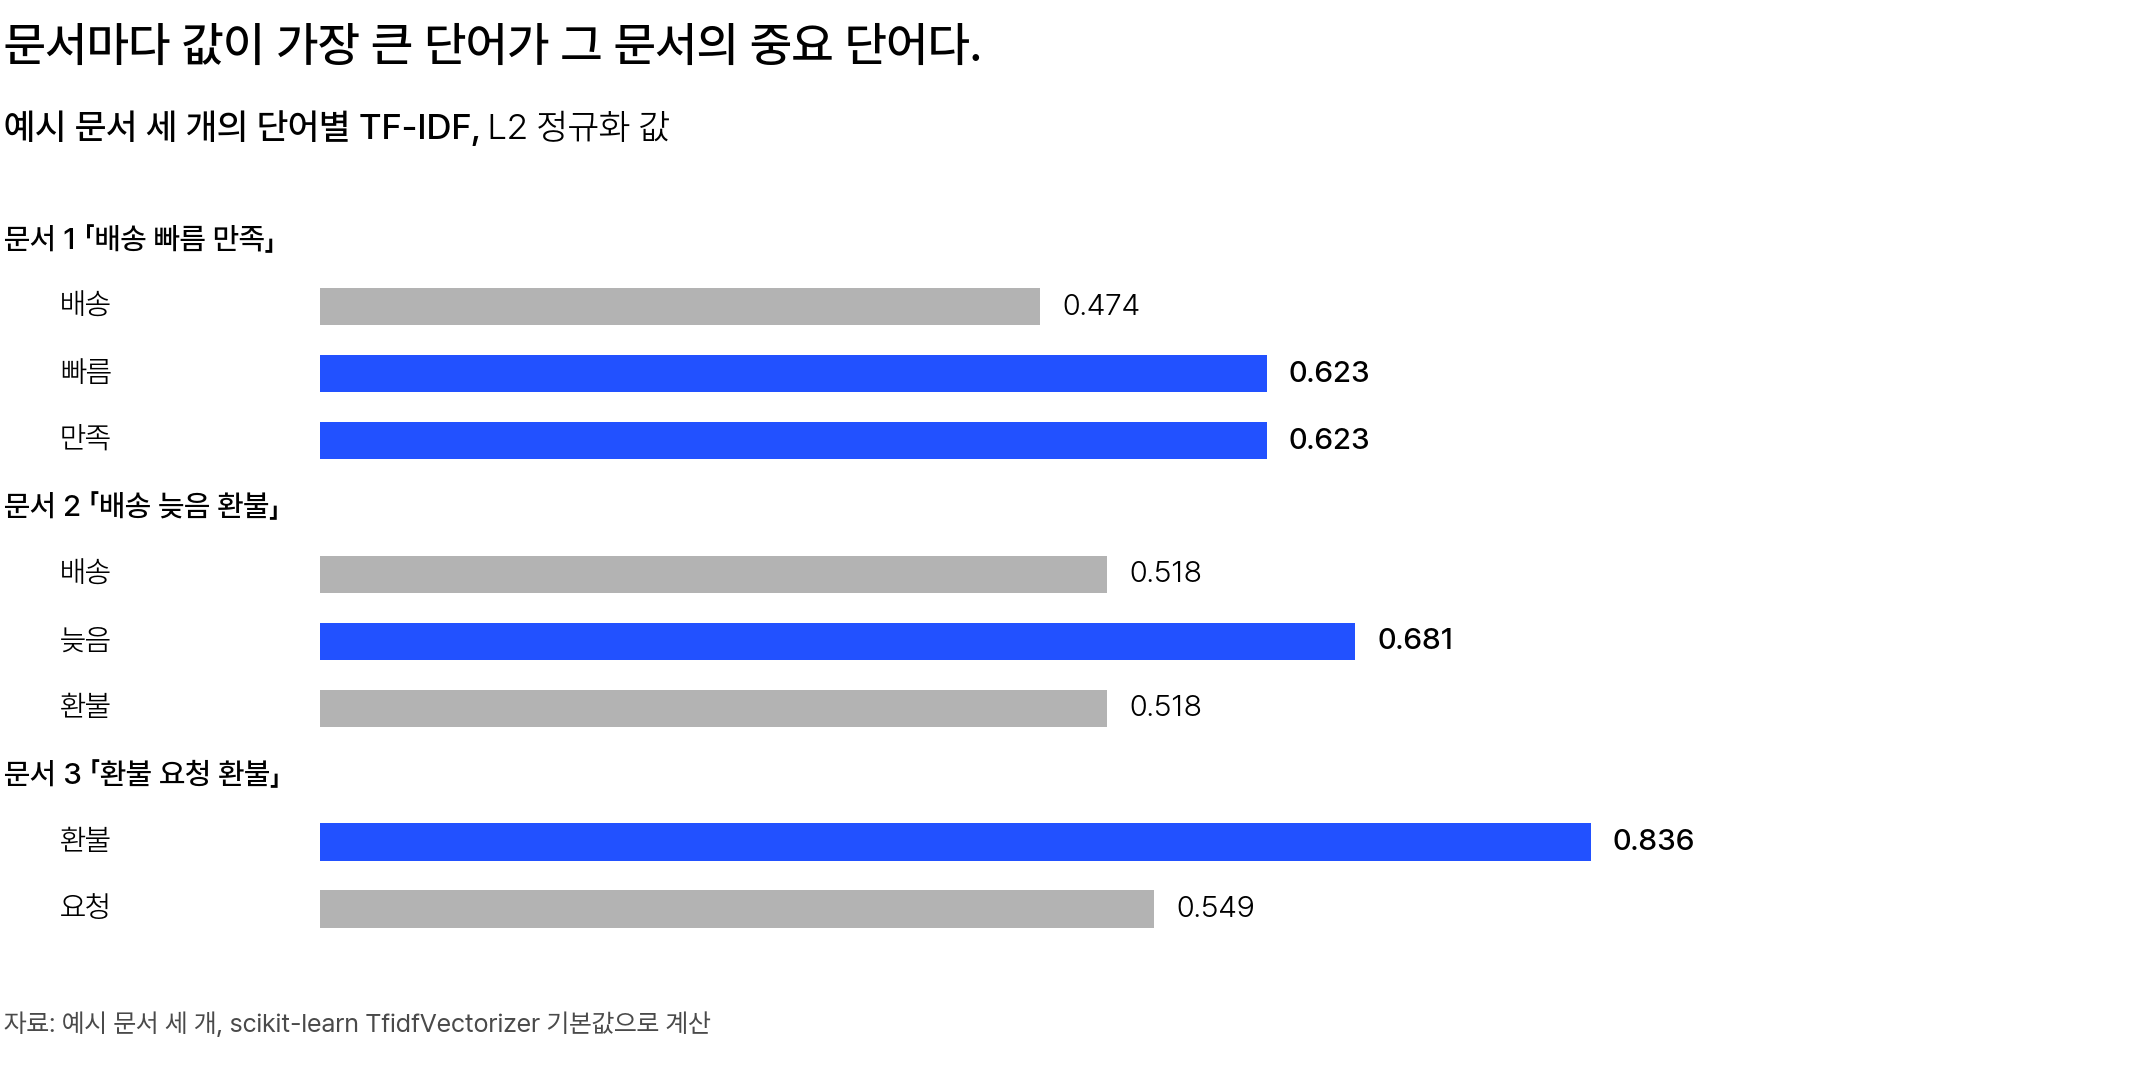

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 예시 문서 세 개의 단어별 TF-IDF(L2 정규화 뒤). 파랑은 문서마다 값이 가장 큰 단어다</em></p>

### 문서 모음이 바뀌면 TF-IDF 도 바뀐다 [필수]

**같은 문서 1 이라도 함께 계산하는 문서가 바뀌면 값이 달라지나요?**

달라집니다. idf 식의 N 과 df 를 문서 모음 전체에서 세기 때문입니다. 아래 코드는 예시 문서 세 개에 문서 하나를 더한 뒤, 문서 1 에서 배송의 값을 다시 계산합니다.

In [ ]:
# 예시 문서 세 개에 문서 하나를 더해 문서 1 「배송 빠름 만족」에서 배송의 값을 다시 계산합니다
from sklearn.feature_extraction.text import TfidfVectorizer

base = ["배송 빠름 만족", "배송 늦음 환불", "환불 요청 환불"]
for added in [None, "배송 늦음", "환불 요청"]:                    # 목록에 다른 문서를 넣어 다시 실행해 봅니다
    corpus = base + ([added] if added else [])
    vec = TfidfVectorizer(token_pattern=r"\S+")                    # 공백으로 자른 단어를 그대로 씁니다
    x = vec.fit_transform(corpus).toarray()                          # L2 정규화까지 마친 TF-IDF
    j = vec.vocabulary_["배송"]
    df = sum("배송" in d.split() for d in corpus)
    print(f"더한 문서 {added or '없음'}: N {len(corpus)} · 배송의 df {df} · "
          f"배송의 idf {vec.idf_[j]:.3f} · 문서 1 배송의 TF-IDF {x[0, j]:.3f}")

| 더한 문서 | N | 배송의 df | 배송의 idf | 문서 1 배송의 TF-IDF |
|---|---:|---:|---:|---:|
| 없음 | 3 | 2 | 1.288 | 0.474 |
| 「배송 늦음」 | 4 | 3 | 1.223 | 0.411 |
| 「환불 요청」 | 4 | 2 | 1.511 | 0.487 |

배송이 있는 문서를 더하면 배송이 더 흔한 말이 되어 값이 내려가고, 없는 문서를 더하면 더 드문 말이 되어 올라갑니다. 그래서 TF-IDF 는 같은 문서 모음에서 계산한 값끼리만 비교합니다.

<div class="lms-summary">

**정리**

- TF-IDF 는 문서 안 비율 tf 에 idf 를 곱한 값입니다. 흔한 단어는 idf 가 작아 점수가 낮아지고, 이 문서에 여러 번 나오면서 다른 문서에는 드문 단어는 점수가 커집니다.
- scikit-learn 은 마지막에 L2 정규화로 문서마다 벡터 길이를 1 로 맞춥니다.

**할 일**

- 손계산과 코드 출력이 어긋나면 L2 정규화를 했는지, 다음으로 idf 식에 1 을 세 곳 모두 더했는지 확인합니다.

TF-IDF 값은 같은 문서 모음에서 계산한 것끼리만 비교합니다.

</div>

> **[문제] 문서가 N = 4 개이고 「환불」이 그중 3개 문서에 나옵니다. scikit-learn 기본식으로 계산한 「환불」의 idf 는 무엇일까요?**
>
> 1. ln(4/3) ≈ 0.288
> 2. ln(5/4) ≈ 0.223
> 3. ln(5/4) + 1 ≈ 1.223
> 4. 1 (여러 문서에 나오므로)

## 2. TF-IDF 로 두 집단을 비교할 때의 한계

TF-IDF 로 「별점 낮은 리뷰가 더 쓰는 단어」를 찾을 수 있을까요? 찾기 어렵습니다. TF-IDF 가 답하는 질문과 지금 필요한 질문이 다르기 때문입니다.

### 집단마다 합친 TF-IDF 의 idf 는 두 값뿐이다 [필수]

**두 질문은 어떻게 다른가요?**

| 값 | 답하는 질문 |
|---|---|
| TF-IDF | 이 문서에서 중요한 단어는 무엇인가 |
| 지금 필요한 값 | 낮은 별점 리뷰가 높은 별점 리뷰보다 더 쓰는 단어는 무엇인가 |

TF-IDF 는 문서 하나를 보는 값이고, 지금 필요한 것은 두 집단을 비교하는 값입니다.

**집단마다 리뷰를 합쳐 문서 하나로 만들면 되지 않나요?**

집단마다 하나씩 만들면 문서는 두 개가 됩니다. 리뷰 8건으로 봅니다.

- 낮은 별점 4건: 「환불 요청」 「환불 배송」 「환불 늦음」 「배송 좋다」
- 높은 별점 4건: 「배송 좋다」 「배송 빠름」 「좋다 만족」 「환불 좋다」

| 집단별 문서 | 내용 |
|---|---|
| 문서 A(낮은 별점 4건을 합침) | 환불 요청 환불 배송 환불 늦음 배송 좋다 |
| 문서 B(높은 별점 4건을 합침) | 배송 좋다 배송 빠름 좋다 만족 환불 좋다 |

문서가 A · B 두 개($N = 2$)라, idf 는 단어가 「두 문서에 다 나왔나」만 봅니다. 식의 분자 1 + N 은 언제나 3 이고, df 는 1 아니면 2 입니다.

$$
\begin{aligned}
\text{A · B 에 다 나온 단어}(\mathrm{df} = 2):\quad & \ln\frac{1 + 2}{1 + 2} + 1 = 0 + 1 = 1 \\
\text{한 문서에만 나온 단어}(\mathrm{df} = 1):\quad & \ln\frac{1 + 2}{1 + 1} + 1 = 0.405 + 1 = 1.405
\end{aligned}
$$

그래서 idf 는 이 두 값뿐입니다.

| 단어 | 낮은 별점 | 높은 별점 | 몰린 쪽 | idf |
|---|---:|---:|---|---:|
| 환불 | 3건 | 1건 | 낮은 별점 | 1 |
| 배송 | 2건 | 2건 | 없음 | 1 |
| 좋다 | 1건 | 3건 | 높은 별점 | 1 |
| 요청 | 1건 | 0건 | 낮은 별점 | 1.405 |

3건 대 1건으로 몰려도, 2건 대 2건으로 반반이어도 idf 는 똑같이 1 입니다. 그래서 낮은 별점 문서 A 에서 반반인 배송(2번 × 1 = 2)이 낮은 별점에만 나온 요청(1번 × 1.405 = 1.405)보다 위에 옵니다.

In [ ]:
# 리뷰 8건(낮은 별점 4건 · 높은 별점 4건)을 집단마다 한 문서로 합쳐 단어마다 idf 를 봅니다
from sklearn.feature_extraction.text import TfidfVectorizer

low = ["환불 요청", "환불 배송", "환불 늦음", "배송 좋다"]      # 낮은 별점 리뷰 4건
high = ["배송 좋다", "배송 빠름", "좋다 만족", "환불 좋다"]     # 높은 별점 리뷰 4건
merged = [" ".join(low), " ".join(high)]                     # 집단마다 합쳐 한 문서로
vec = TfidfVectorizer(token_pattern=r"\S+").fit(merged)
for j, w in enumerate(vec.get_feature_names_out()):
    a = sum(w in r.split() for r in low)
    b = sum(w in r.split() for r in high)
    print(f"{w}: 낮은 별점 {a}건 · 높은 별점 {b}건 · idf {vec.idf_[j]:.3f}")

**실제 리뷰 2만 건에서는 왜 상위 단어의 idf 가 모두 1 인가요?**

idf 는 단어가 몇 번 나왔는지가 아니라, 나온 문서가 몇 개인지만 봅니다. 실제 리뷰도 집단마다 1만 건쯤을 합쳐 문서 두 개로 만듭니다. 그 긴 문서에 한 번이라도 나오면 「나온 문서」로 칩니다. 그래서 1번 나와도, 1,000번 나와도 df 는 같습니다.

| 경우 | df | idf | 어휘 9,873개 가운데 | 예 |
|---|---:|---:|---:|---|
| 두 집단에 모두 한 번 이상 | 2 | 1 | 3,719개 | 하다 · 쓰다 · 좋다 |
| 한 집단에만 | 1 | 1.405 | 6,154개 | 최악 |

어휘 수로 보면 한 집단에만 나온 단어가 더 많지만, 대부분 몇 번 안 나오는 드문 단어입니다. 그 가운데 가장 많이 나온 「최악」도 124번입니다. 수백 번 나오는 단어가 다른 집단 리뷰 1만 건에 한 번도 안 나오기는 어렵습니다. 그래서 자주 나오는 단어는 idf 가 모두 1 이고, 많이 나온 순서대로 위에 옵니다.

별점 1·2점 리뷰를 모두 합쳐 만든 문서의 TF-IDF 상위입니다.

| 순위 | 단어 | 합쳐 만든 문서에 나온 횟수 | idf | TF-IDF(정규화 뒤) |
|---|---|---:|---:|---:|
| 1 | 하다 | 2,189 | 1 | 0.396 |
| 2 | 쓰다 | 1,636 | 1 | 0.296 |
| 3 | 되다 | 1,269 | 1 | 0.230 |
| 4 | 좋다 | 1,231 | 1 | 0.223 |
| 상위 10 밖 | 최악 | 124 | 1.405 | 0.032 |

「좋다」는 4·5점 리뷰의 42%, 1·2점 리뷰의 11% 가 쓰는 높은 별점 쪽 단어인데도 낮은 별점 쪽 4위입니다. idf 가 1.405 인 「최악」은 124번뿐이라 0.032 에 그칩니다.

그래서 합친 TF-IDF 순위로는 특징 단어를 고르지 않습니다.

### 비율의 비는 건수가 적으면 크게 달라진다 [필수]

**그러면 두 집단을 어떻게 비교하나요?**

가장 쉬운 방법은 「100건 가운데 몇 건이 그 단어를 썼나」를 두 집단에서 비교하는 것입니다. 앞 예의 환불은 낮은 별점 75%(4건 가운데 3건), 높은 별점 25%(4건 가운데 1건)라 3배입니다. 이 배수가 **비율의 비**입니다.

**배수만 보면 되나요?**

아닙니다. 몇 건에서 나온 배수인지도 봐야 합니다. 반품은 8건이 6건이나 10건만 되어도 배수가 크게 바뀝니다.

| 단어 | 별점 1·2점 | 별점 4·5점 | 비 | 4·5점 쪽이 두 건 달라지면 |
|---|---:|---:|---:|---:|
| 없다 | 1,028건(10.33%) | 388건(3.86%) | 약 2.7배 | 2.66～2.69배 |
| 반품 | 404건(4.06%) | 8건(0.08%) | 약 51배 | 41～68배 |

8건에서 나온 51배는 두 건만 달라져도 크게 바뀌고, 388건에서 나온 2.7배는 거의 그대로입니다. 배수와 건수를 한 값으로 함께 보는 방법이 「3. 가중 로그 오즈」입니다.

<details class="lms-extra"><summary>더 깊이 — 건수가 적은 비율이 크게 달라지는 이유</summary>

주사위를 몇 번만 던지면 나온 눈의 평균이 크게 오르내리고, 수백 번을 던지면 3.5 가까이에 머뭅니다. 이것을 **큰 수의 법칙(law of large numbers)** 이라고 합니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/f9/Largenumbers.svg" alt="주사위를 던진 횟수에 따른 평균의 움직임" width="640" height="512" />
<p align="center"><em>▲ 주사위를 던진 횟수(가로축 trials, 0～1,000번)에 따라 지금까지 나온 눈의 평균(빨간 선, 세로축 mean value)이 움직이는 모습. 처음 수십 번은 크게 오르내리고 수백 번이 지나면 초록 선 3.5 가까이에서 크게 벗어나지 않는다 (출처: Wikimedia Commons, CC0)</em></p>

문서 비율도 이런 평균입니다. 그 단어를 쓴 리뷰를 1, 안 쓴 리뷰를 0 으로 두면, 리뷰 $n$ 건 가운데 $y$ 건이 쓴 비율 $p = y/n$ 은 0 과 1 의 평균입니다. 비율이 표본마다 달라지는 보통 크기는 표준오차 $\sqrt{p(1-p)/n}$ 이고, 이를 $p$ 로 나누면 비율 자신의 몇 % 인지가 됩니다.

$$
\begin{aligned}
\frac{1}{p}\sqrt{\frac{p(1-p)}{n}} &= \sqrt{\frac{p(1-p)}{p^2 n}} \\
&= \sqrt{\frac{1-p}{pn}} \\
&= \sqrt{\frac{1-p}{y}} \\
&\approx \frac{1}{\sqrt{y}}
\end{aligned}
$$

- 첫 등호: $1/p$ 를 제곱해 루트 안으로 옮깁니다
- 둘째 등호: 분자와 분모의 $p$ 하나를 약분합니다
- 셋째 등호: $pn = y$ 입니다
- $\approx$: $p$ 가 작아 $1-p$ 를 1 로 어림합니다

4·5점 쪽 「반품」은 8건이라 1/√8 ≈ 0.35, 비율이 제 크기의 35% 쯤 달라집니다. 1·2점 쪽 404건이면 1/√404 ≈ 0.05 입니다. 비의 분모인 4·5점 쪽 비율이 35% 달라지면 비도 그만큼 달라집니다.

</details>

<div class="lms-summary">

**정리**

- 집단마다 합치면 idf 가 1 과 1.405 뿐이라, TF-IDF 순위는 많이 나온 순서가 됩니다.
- 비율의 비는 차이를 보여 주지만, 건수가 적으면 크게 달라집니다.

**할 일**

- 특징 단어를 합친 TF-IDF 순위로 고르지 않습니다.

비의 크기와 건수를 함께 보는 값이 필요합니다.

</div>

> **[문제] 한 문서로 합친 TF-IDF 에서 「좋다」가 별점 1·2점 쪽 4위인 이유**
>
> 별점 1·2점 리뷰를 모두 한 문서로 합치고, 4·5점 리뷰도 한 문서로 합쳐 두 문서로 TF-IDF 를 계산했습니다. 긍정 단어인 「좋다」가 별점 1·2점 쪽 문서의 TF-IDF 순위 4위에 올랐습니다. 그 이유를 idf 값으로 한두 문장 적어 보세요.

## 3. 가중 로그 오즈

20대 대 60대 이상 민원에서 「수강」은 9건 대 0건, 「환불」은 612건 대 265건에 나옵니다. 수강은 20대 쪽에만 나왔고, 환불은 비율로 약 2.6배입니다. 어느 쪽을 20대의 특징 단어라고 더 자신 있게 말할 수 있을까요?

한쪽이 0건인 단어가 어떻게 되는지 보기 쉬워서, 방법은 민원으로 익히고 끝에서 별점 리뷰에 씁니다.

### 로그 오즈 차이란 무엇인가 [필수]

**오즈는 무엇인가요?**

**오즈(odds)** 는 쓴 리뷰 수 ÷ 안 쓴 리뷰 수입니다. 4건 가운데 3건이 쓰면 3 ÷ 1 = 3 입니다. 비율로는 75% 이고, 쓴 리뷰와 안 쓴 리뷰가 3 : 1 입니다. 낮은 별점 오즈를 높은 별점 오즈로 나눈 값이 **오즈비(odds ratio)** 이고, 오즈비에 로그를 씌운 값이 **로그 오즈 차이**입니다. ln(A ÷ B) = ln A − ln B 라서 두 로그 오즈의 「차이」라고 부릅니다.

| 단어 | 낮은 별점 쓴 : 안 쓴 → 오즈 | 높은 별점 쓴 : 안 쓴 → 오즈 | 오즈비 | 로그 오즈 차이 |
|---|---:|---:|---:|---:|
| 환불 | 3 : 1 → 3 | 1 : 3 → 1/3 | 9 | ln 9 = +2.20 |
| 배송 | 2 : 2 → 1 | 2 : 2 → 1 | 1 | ln 1 = 0 |
| 좋다 | 1 : 3 → 1/3 | 3 : 1 → 3 | 1/9 | ln(1/9) = −2.20 |

- 양수: 낮은 별점 쪽이 더 쓰는 단어(환불)
- 음수: 높은 별점 쪽이 더 쓰는 단어(좋다)
- 0 에 가까움: 두 쪽이 비슷하게 쓰는 단어(배송)

오즈비는 비율의 비와 다른 수입니다. 환불은 비율로 3배(75% 대 25%)지만 오즈비는 9 입니다. 비율이 10% 아래인 단어는 오즈와 비율이 거의 같아, 오즈비도 비율의 비와 거의 같습니다. 그래도 오즈를 쓰는 것은 로그 오즈 차이의 분산을 쓴 문서 수로 간단히 구할 수 있어, 뒤에서 $z$ 를 바로 계산할 수 있기 때문입니다.

**TF-IDF 와 무엇이 다른가요?**

로그 오즈 차이는 두 집단의 오즈가 몇 배 차이 나는지를 로그로 바꾼 값입니다. TF-IDF 와 비교하면 아래와 같습니다.

| 항목 | TF-IDF | 로그 오즈 차이 · 가중 로그 오즈 |
|---|---|---|
| 묻는 것 | 이 문서에서 이 단어가 얼마나 중요한가 | 두 집단 가운데 어느 쪽이 이 단어를 더 쓰는가 |
| 비교 대상 | 한 문서 대 전체 문서 | 집단 A 대 집단 B |
| 결과 | 문서마다 단어 가중치(0 이상) | 방향이 있는 점수(양수 · 음수) |
| 흔한 단어 | 여러 문서에 나오면 idf 가 작아진다 | 두 집단이 비슷하게 쓰면 0 에 가까워진다 |

**왜 로그를 씌우나요?**

9배 더 쓰는 것과 9배 덜 쓰는 것은 차이의 크기가 같습니다. 그런데 오즈비로는 9 와 0.11 이라 크기가 달라 보입니다. 로그를 씌우면 +2.20 과 −2.20 으로 크기가 같아집니다.

**한쪽이 0건이면 어떻게 하나요?**

0건이면 오즈가 0 이라 로그를 씌울 수 없습니다. 그래서 쓴 수와 안 쓴 수에 0.5 씩 더합니다.

$$
\text{보정 없는 로그 오즈} = \ln\frac{y_a + 0.5}{n_a - y_a + 0.5} - \ln\frac{y_b + 0.5}{n_b - y_b + 0.5}
$$

- $n_a$, $n_b$: 두 집단의 문서 수
- $y_a$, $y_b$: 두 집단에서 그 단어를 쓴 문서 수(한 문서에 두 번 나와도 1)
- $n - y$: 그 단어를 쓰지 않은 문서 수

0.5 만 더해 구한 이 값을 **보정 없는 로그 오즈(raw log odds)** 라고 합니다. 0건만 피했을 뿐, 건수가 적은 것은 따로 고려하지 않았다는 뜻의 이름입니다.

**보정 없는 로그 오즈로 정렬하면 무엇이 문제인가요?**

건수가 적은 단어가 위로 옵니다. 민원 표본의 20대 2,175건과 60대 이상 2,446건에서 두 집단 문서 합이 5건 이상인 명사 703개를 정렬했습니다.

| 순위 | 단어 | 20대 · 60대 이상 문서 | 보정 없는 로그 오즈 |
|---:|---|---:|---:|
| 1 | 수강 | 9 · 0 | 3.07 |
| 89 | 환불 | 612 · 265 | 1.17 |

수강은 60대 이상이 0건이라 차이가 크게 나옵니다. 하지만 60대 이상 쪽에 수강 민원이 1건만 생겨도 3.07 이 1.97 로, 2건이면 1.46 으로 줄어듭니다. 앞에서 본 반품의 51배와 같은 문제입니다.

<details class="lms-extra"><summary>자세히 — 0건인 쪽이 있으면 로그 오즈 차이가 커지는 이유</summary>

<img src="https://upload.wikimedia.org/wikipedia/commons/c/c8/Logit.svg" alt="비율을 로그 오즈로 바꾼 곡선" width="640" height="417" />
<p align="center"><em>▲ 비율 x(가로축 0～1)를 로그 오즈 ln(x ÷ (1 − x))(세로축)로 바꾼 곡선으로, x 가 0 에 가까울수록 가파르게 작아진다 (출처: Wikimedia Commons, CC0)</em></p>

0건인 쪽은 0.5 를 더해도 비율이 0 에 가까워 곡선의 왼쪽 끝에 있습니다. 그래서 다른 쪽이 몇 건뿐이어도 차이가 크게 나옵니다.

</details>

### 가중 로그 오즈란 무엇인가 [필수]

**한 줄로 말하면 무엇인가요?**

**가중 로그 오즈(weighted log odds)** 는 로그 오즈 차이를 그 표준오차로 나눈 값 $z$ 입니다. 「가중」은 건수가 많은 단어의 차이를 더 크게 반영한다는 뜻입니다.

**왜 나누나요?**

리뷰 한 건뿐인 상품의 별점 5.0 보다, 리뷰 수백 건인 상품의 별점 4.8 을 더 믿습니다. 리뷰가 한 건인 별점은 다음 리뷰 하나로 크게 바뀌기 때문입니다. 단어도 같습니다.

- 여러 문서에서 나온 차이는 잘 바뀌지 않으니 크게 반영합니다.
- 몇 건에서만 나온 차이는 우연일 수 있으니 작게 반영합니다.

**0.5 대신 무엇을 더하나요?**

**사전 문서 수(prior)** 를 더합니다. 가상의 문서 1,000건($\alpha_0$)을 단어 703개에 나눠 주는데, 그 단어가 나온 문서 수에 비례해 줍니다.

| 단어 | 두 집단 문서 합 | 사전 문서 수 |
|---|---:|---:|
| 환불 | 877건 | 1,000 × 877 ÷ 23,295 = 37.65 |
| 수강 | 9건 | 1,000 × 9 ÷ 23,295 = 0.3863 |

23,295 는 단어 703개의 두 집단 문서 합을 모두 더한 수입니다. 사전 문서 수는 0건을 피하게 하고, 많이 더할수록 건수가 적은 단어의 차이를 줄입니다. 이 수업의 α₀ 1,000 에서 순위를 크게 바꾸는 것은 아래의 나누는 단계입니다.

**z 는 어떻게 구하나요?**

로그 오즈 차이를 표준오차로 나눕니다. 표준오차는 표본을 다시 추출했을 때 추정한 차이가 보통 얼마나 달라지는지이고, 건수가 적을수록 큽니다. 자료 값 하나하나의 표준편차가 아니라, 차이라는 추정치 하나의 표준오차입니다.

$$
z_w = \frac{\hat\delta_w}{\sqrt{\hat\sigma^2_w}}
$$

- $\hat\delta_w$: 사전 문서 수를 더해 구한 단어 $w$ 의 로그 오즈 차이
- $\hat\sigma^2_w$: 그 차이의 분산(표준오차의 제곱). 집단마다 1 ÷ (쓴 문서 수 + 사전 문서 수) 를 구해 더합니다

사전 문서 수를 빼고 어림하면, 쓴 문서가 9건이면 1 ÷ 9 = 0.11, 600건이면 1 ÷ 600 = 0.0017 입니다. 건수가 적을수록 분산이 커져 $z$ 가 작아집니다. $z$ 가 2 면 차이가 표준오차의 2배, 14 면 14배라는 뜻입니다. 두 집단에 차이가 없다면 $|z|$ 가 2 를 넘는 일은 드물고(약 5%), 14 를 넘는 일은 사실상 없습니다.

<details class="lms-extra"><summary>자세히 — 가중 로그 오즈의 식 네 개와 「환불」 대입</summary>

「환불」(20대 612건 · 60대 이상 265건)을 네 식에 차례로 대입합니다. $n_a = 2{,}175$, $n_b = 2{,}446$, $\alpha_0 = 1{,}000$ 입니다.

첫째 식은 사전 문서 수입니다. 분자에 877 을, 분모에 23,295 를 대입합니다.

$$
\begin{aligned}
\text{식:}\quad & \alpha_w = \alpha_0 \times \frac{y_{a,w} + y_{b,w}}{\sum_v (y_{a,v} + y_{b,v})} \\
\text{대입한다:}\quad & \alpha_w = 1{,}000 \times \frac{877}{23{,}295} = 37.65
\end{aligned}
$$

둘째 식은 사전 문서 수를 더한 로그 오즈 차이입니다. 분자는 쓴 문서, 분모는 쓰지 않은 문서입니다.

$$
\begin{aligned}
\text{식:}\quad & \hat\delta_w = \ln\frac{y_{a,w} + \alpha_w}{n_a + \alpha_0 - y_{a,w} - \alpha_w} - \ln\frac{y_{b,w} + \alpha_w}{n_b + \alpha_0 - y_{b,w} - \alpha_w} \\
\text{대입한다:}\quad & \hat\delta_w = \ln\frac{612 + 37.65}{2{,}175 + 1{,}000 - 612 - 37.65} - \ln\frac{265 + 37.65}{2{,}446 + 1{,}000 - 265 - 37.65} \\
\text{분자와 분모를 계산한다:}\quad & \hat\delta_w = \ln\frac{649.65}{2{,}525.35} - \ln\frac{302.65}{3{,}143.35} \\
\text{로그를 계산해 뺀다:}\quad & \hat\delta_w = -1.3577 - (-2.3405) = 0.9828
\end{aligned}
$$

셋째 식은 분산으로, 둘째 식의 두 분자를 분모에 대입해 더합니다. 넷째 식은 차이를 분산의 제곱근으로 나눠 $z$ 를 구합니다.

$$
\begin{aligned}
\text{분산:}\quad & \hat\sigma^2_w = \frac{1}{649.65} + \frac{1}{302.65} = 0.004843 \\
\text{제곱근으로 나눈다:}\quad & z_w = \frac{0.9828}{\sqrt{0.004843}} = \frac{0.9828}{0.0696} = 14.12
\end{aligned}
$$

분산 식은 Monroe, Colaresi, Quinn(2008)의 근사입니다. 버린 항까지 포함하면 환불의 $z$ 는 13.18 이지만, 양쪽 상위 10 은 단어도 순서도 같습니다.

</details>

아래 코드는 환불과 수강의 $\alpha_w$ · $\hat\delta$ · 분산 · $z$ 를 계산합니다.

In [ ]:
# 가중 로그 오즈 손계산: 민원 표본 2만, 20대 2,175건 대 60대 이상 2,446건, 명사 문서 단위
import math

N_20, N_60 = 2175, 2446        # 두 집단의 문서 수
TOTAL = 23295                  # 단어 703개의 두 집단 문서 합을 모두 더한 값
A0 = 1000                      # 사전 문서 수의 합 α₀: 10 이나 10000 으로 바꿔 수강·환불의 δ 와 z 를 비교해 본다


def wlo(y20, y60, a0=A0):
    aw = a0 * (y20 + y60) / TOTAL                          # 이 단어의 사전 문서 수 αw
    lo20 = math.log((y20 + aw) / (N_20 + a0 - y20 - aw))   # 20대 로그 오즈
    lo60 = math.log((y60 + aw) / (N_60 + a0 - y60 - aw))   # 60대 이상 로그 오즈
    delta = lo20 - lo60                                    # 로그 오즈 차이 δ
    var = 1 / (y20 + aw) + 1 / (y60 + aw)                  # 분산 σ² 근사
    return aw, delta, var, delta / math.sqrt(var)


for word, y20, y60 in [("환불", 612, 265), ("수강", 9, 0)]:
    aw, delta, var, z = wlo(y20, y60)
    raw = math.log((y20 + 0.5) / (N_20 - y20 + 0.5)) - math.log((y60 + 0.5) / (N_60 - y60 + 0.5))
    print(f"{word}: αw {aw:.4f} · δ {delta:.4f} · σ² {var:.4g} · z {z:.2f} · 보정 없는 로그 오즈 {raw:.2f}")

| 단어 | 20대 · 60대 이상 문서 | 차이 $\hat\delta$ | 표준오차 | $z$ | $z$ 순위 |
|---|---|---:|---:|---:|---:|
| 환불 | 612 · 265 | 0.9828 | 0.0696 | 14.12 | 1위 |
| 수강 | 9 · 0 | 3.2750 | 1.642 | 2.00 | 65위 |

그래서 20대의 특징 단어로 더 자신 있게 말할 수 있는 쪽은 환불입니다.

- 환불: 차이는 0.98 로 작지만, 표준오차(0.07)의 14배입니다.
- 수강: 차이는 3.28 로 환불의 약 3.3배지만, 표준오차(1.64)의 2배뿐입니다.

수강은 60대 이상이 0건이라 분산의 그쪽 항이 1 ÷ (0 + 0.3863) ≈ 2.59 로 큽니다. 그래서 분산이 2.695, 표준오차가 1.64 가 됩니다.

수강의 $z$ 2.00 은 아래 기준 1.96 을 겨우 넘지만, α₀ 를 10 으로 하면 0.49 로 떨어질 만큼 불안정합니다.

그러면 $z$ 가 얼마나 커야 할까요? 단어 하나만 비교할 때, 차이가 없는데도 $|z|$ 가 1.96 을 넘는 경우는 20번에 1번(5%)입니다. 그래서 $|z| > 1.96$ 이면 우연만으로 생긴 차이로 보기 어렵습니다. 단어 703개를 한꺼번에 비교할 때의 기준은 「4. 우연으로 생긴 차이」에서 다룹니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/8/8c/Standard_deviation_diagram.svg" alt="정규분포를 표준편차 간격으로 나눈 넓이" width="640" height="320" />
<p align="center"><em>▲ 정규분포를 표준편차(σ) 간격으로 나눈 넓이로, 안쪽 넓이가 정확히 95% 가 되는 경계는 ±1.96σ 다 (출처: Wikimedia Commons, CC BY 2.5)</em></p>

<details class="lms-extra"><summary>자세히 — 20대 쪽 · 60대 이상 쪽 z 상위 10</summary>

단어 옆 수는 20대 문서 / 60대 이상 문서입니다.

| 20대 쪽 | $z$ | 60대 이상 쪽 | $z$ |
|---|---:|---|---:|
| 환불 612/265 | 14.12 | 수리 35/125 | −6.15 |
| 헬스장 100/7 | 7.47 | 주식 4/60 | −5.34 |
| 취소 256/155 | 5.98 | 투자 10/63 | −5.13 |
| 중도 92/35 | 5.24 | 홈쇼핑 1/57 | −5.03 |
| 예약 56/11 | 5.17 | 여행 24/85 | −5.01 |
| 학원 48/3 | 5.13 | 문자 12/54 | −4.37 |
| 철회 73/27 | 4.73 | 정수기 11/50 | −4.21 |
| 필라테스 35/2 | 4.36 | 자문 9/46 | −4.18 |
| 규정 59/21 | 4.33 | 청구 42/100 | −4.17 |
| 항공 51/18 | 4.04 | 냉장고 7/42 | −4.14 |

</details>

아래 그림은 두 정렬의 20대 쪽 상위 10 이 각각 문서 몇 건에서 나온 단어인지 비교합니다.

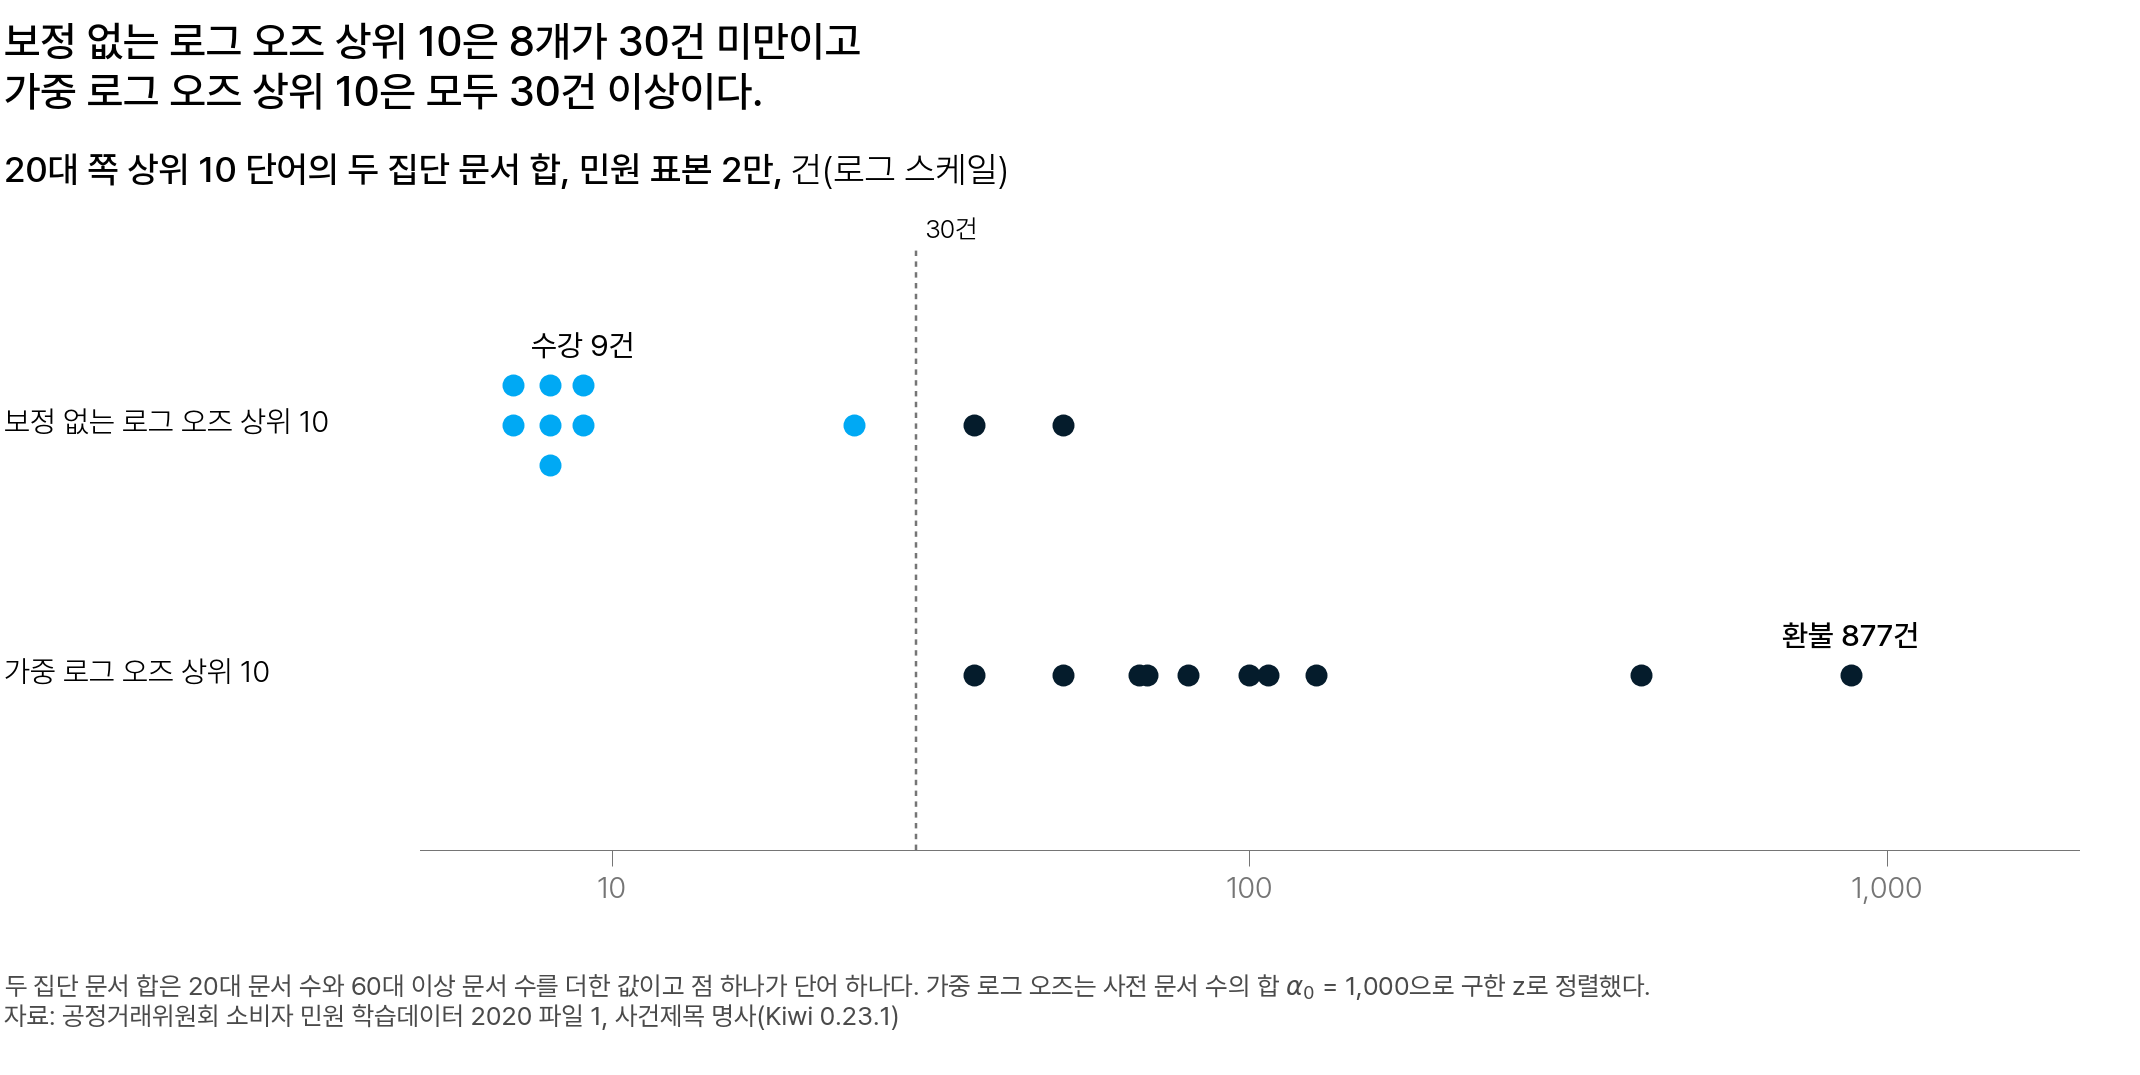

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 20대 쪽 상위 10 단어의 두 집단 문서 합. 점 하나가 단어 하나이고, 가로축은 로그 스케일, 점선은 30건이다. 위 줄은 보정 없는 로그 오즈로, 아래 줄은 가중 로그 오즈로 고른 10개다</em></p>

가중 로그 오즈로 고른 10개는 모두 두 집단 문서 합이 30건 이상입니다.

**사전 문서 수 1,000 을 바꾸면 결론도 바뀌나요?**

환불이 수강보다 위라는 결론은 바뀌지 않습니다. 다만 수강이 1.96 을 넘는지는 α₀ 에 따라 달라집니다. α₀ 는 분석가가 정하는 값이고 이 수업은 1,000 을 씁니다. α₀ 를 10 · 1,000 · 10,000 으로 바꿔 환불과 수강의 z 를 다시 계산합니다.

In [ ]:
# 환불과 수강의 δ · 표준오차 · z 를 α₀ 10 · 1,000 · 10,000 에서 계산합니다(위 손계산 셀과 같은 식)
import math
import pandas as pd

N_20, N_60, TOTAL = 2175, 2446, 23295          # 두 집단의 문서 수 · 단어 703개의 두 집단 문서 합의 합


def wlo(y20, y60, a0):
    aw = a0 * (y20 + y60) / TOTAL                                   # 이 단어의 사전 문서 수 αw
    delta = (math.log((y20 + aw) / (N_20 + a0 - y20 - aw))
             - math.log((y60 + aw) / (N_60 + a0 - y60 - aw)))       # 로그 오즈 차이 δ
    sd = math.sqrt(1 / (y20 + aw) + 1 / (y60 + aw))                 # 표준오차 σ
    return aw, delta, sd, delta / sd


rows = [dict(zip(["단어", "α₀", "αw", "δ", "표준오차", "z"], [w, a0, *wlo(y20, y60, a0)]))
        for w, y20, y60 in [("환불", 612, 265), ("수강", 9, 0)] for a0 in [10, 1000, 10000]]
table = pd.DataFrame(rows).round({"αw": 4, "δ": 2, "표준오차": 2, "z": 2}).set_index("단어")
DIGITS = {"αw": 4, "δ": 2, "표준오차": 2, "z": 2}                                   # 반올림 자릿수 그대로 찍기(끝자리 0 포함)
table = table.apply(lambda col: col.map(("{:.%df}" % DIGITS[col.name]).format) if col.name in DIGITS else col)
for name, *vals in table.itertuples():
    print(f"{name}: " + " · ".join(f"{k} {v}" for k, v in zip(table.columns, vals)))

| α₀ | 수강의 차이 $\hat\delta$ | 수강의 $z$ | 환불의 $z$ |
|---:|---:|---:|---:|
| 10 | 7.87 | 0.49 | 15.89 |
| 1,000 | 3.28 | 2.00 | 14.12 |
| 10,000 | 1.23 | 2.11 | 9.59 |

$z$ 의 크기는 달라져도 세 경우 모두 환불이 수강보다 큽니다.

> **[문제] 문서 단위로 집계하는 이유**
>
> 가중 로그 오즈는 단어의 수를 「문서 단위」로 구합니다. 민원 제목 하나에 「환불」이 두 번 나와도 y 는 1 만 늘어납니다. 문서 비율을 배울 때 민원 표본 2만 건에서 「환불」은 토큰으로 3,658번, 문서로 3,550건이었습니다. 두 수가 108 차이 나는 이유와, 이 계산이 문서 수를 쓰는 이유를 한두 문장으로 적어 보세요.

### 별점 리뷰의 특징 단어 [필수]

**처음 질문의 답은 무엇인가요?**

민원으로 익힌 가중 로그 오즈를 처음 질문인 별점 리뷰에 그대로 씁니다. 별점 1·2점 리뷰 9,947건과 4·5점 리뷰 10,053건에서, 두 집단 문서 합이 5건 이상인 단어 2,748개의 $z$ 를 구했습니다. 별점 차이는 「좋다 · 없다」 같은 형용사 · 동사에 많이 드러나서, 리뷰는 명사와 용언(동사 · 형용사)을 함께 집계합니다.

- $z$ 양수: 1·2점 쪽이 더 쓰는 단어. 1위는 「없다」입니다.
- $z$ 음수: 4·5점 쪽이 더 쓰는 단어. 1위는 「좋다」입니다.

아래 그림은 양쪽 상위 10 입니다. 막대 길이 $|z|$ 는 차이가 표준오차의 몇 배인지입니다.

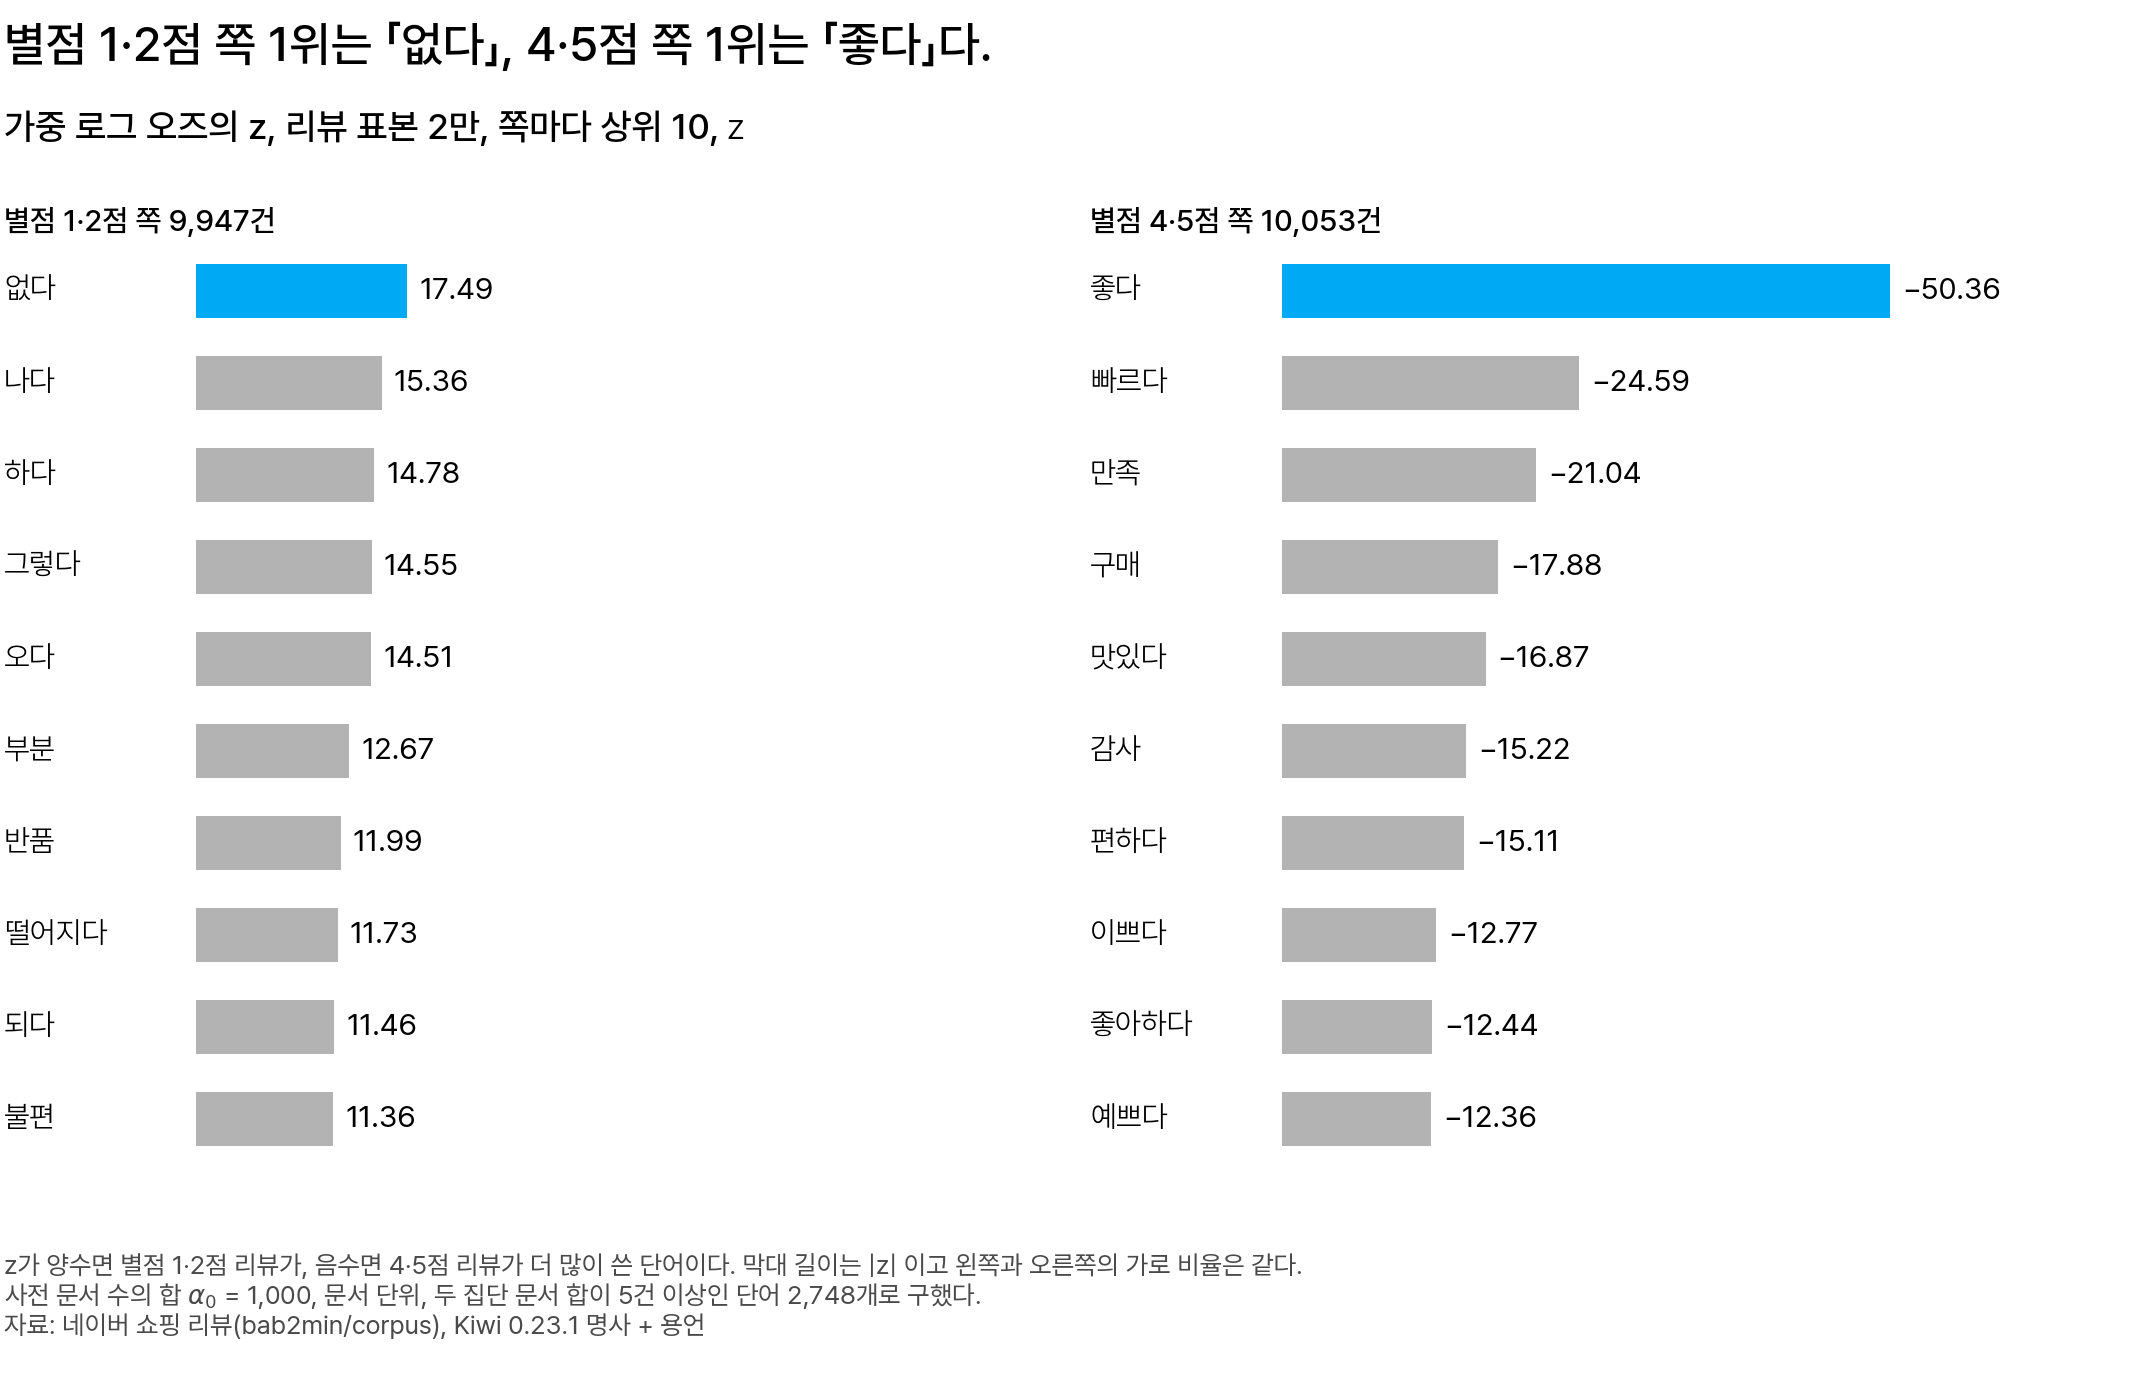

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가중 로그 오즈 상위 10 씩. 막대 길이는 |z| 이고, 왼쪽은 별점 1·2점 쪽(z 양수), 오른쪽은 4·5점 쪽(z 음수)이다. 두 쪽의 가로 비율은 같고, 하늘색 막대가 쪽마다 1위다</em></p>

**1위 두 단어의 $z$ 는 어떻게 읽나요?**

| 단어 | 별점 1·2점 문서 비율 | 별점 4·5점 문서 비율 | $z$ |
|---|---:|---:|---:|
| 없다 | 10.33% | 3.86% | 17.49 |
| 좋다 | 11.12% | 41.89% | −50.36 |

- 없다: 1·2점 쪽이 더 씁니다. 이 차이는 표준오차의 약 17배라 우연으로 보기 어렵습니다.
- 좋다: 4·5점 쪽이 더 씁니다(음수). 비율 차이가 더 크고 쓴 문서도 많아, $|z|$ 가 없다의 약 3배입니다.

TF-IDF 에서 1·2점 쪽 4위였던 「좋다」가 여기서는 4·5점 쪽 1위입니다. 비율의 비로 2.7배였던 「없다」(388건)는 1위가 되고, 51배였던 「반품」(4·5점 쪽 8건)은 7위입니다. 가중 로그 오즈가 배수와 건수를 함께 반영한 결과입니다.

「하다 · 나다 · 오다」처럼 뜻이 넓은 말도 1·2점 쪽 위에 오는데, 어떤 문장에서 쓰였는지는 원문으로 확인합니다. 그래서 별점 낮은 리뷰에는 「없다 · 반품 · 불편 · 떨어지다」가, 높은 리뷰에는 「좋다 · 빠르다 · 만족」이 더 자주 나옵니다.

**z 만으로 말할 수 없는 것은?**

단어가 쓰인 뜻입니다. 「좋지 않아요」를 형태소로 잘라도 「좋다」가 남습니다. 그래서 $z$ 로는 4·5점 쪽이 「좋다」를 더 자주 쓴다고는 말할 수 있지만, 모두 만족해서 썼다고는 말할 수 없습니다. 원문을 몇 건 읽어 확인합니다.

<div class="lms-summary">

**정리**

- 로그 오즈 차이는 두 집단 오즈비에 로그를 씌운 값입니다. 부호는 방향, 크기는 차이입니다.
- 보정 없는 로그 오즈로 정렬하면 건수가 적은 단어가 위로 옵니다.
- 가중 로그 오즈는 차이를 표준오차로 나눈 $z$ 로 정렬해, 건수가 적은 큰 차이가 위로 오지 않게 합니다.

**할 일**

- 특징 단어는 $z$ 순서로 고르고, 상위 단어마다 두 집단 문서 수와 원문 몇 건을 확인합니다

$z$ 는 차이가 표준오차의 몇 배인지입니다.

</div>

> **[문제] 보정 없는 로그 오즈와 가중 로그 오즈의 순위가 반대가 된 이유**
>
> 20대 대 60대 이상 민원에서 「수강」은 9건 대 0건, 「환불」은 612건 대 265건입니다. 보정 없는 로그 오즈 순위는 수강 1위·환불 89위입니다. 가중 로그 오즈(α₀ 1,000)의 z 순위는 수강 65위(z 2.00)·환불 1위(z 14.12)입니다. 순위가 반대가 된 이유를 분산 항으로 한두 문장 적어 보세요.

## 4. 우연으로 생긴 차이

별점 비교에서는 어휘 2,748개 가운데 762개의 $|z|$ 가 1.96 을 넘었습니다. 이 가운데 진짜 차이 없이 우연히 넘은 단어는 몇 개쯤일까요?

### 무작위 분할 비교 [필수]

**차이가 없어도 기준을 넘는 단어가 나오나요?**

나옵니다. 주사위를 한 번 던져 6 이 나올 확률은 1/6 이지만, 20번 던지면 97% 확률로 한 번은 나옵니다. 단어도 같습니다. 단어 하나가 우연히 1.96 을 넘을 확률은 5% 입니다. 그래도 차이 없는 단어 2,748개를 비교하면 약 137개가 우연히 넘을 수 있습니다. 통계적 검정과 인과추론 수업에서 본 **다중비교 문제(multiple comparisons)** 입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/7/70/Multiple_binomial_testing.svg" alt="파랑과 빨강 점 10개씩으로 된 표본 30개를 격자로 배치하고 표본마다 p 값을 적은 그림 — 하나만 p = 0.0215 로 보라색 원이 둘러져 있다" width="560" height="560"/>
<p align="center"><em>▲ 두 색이 같은 확률로 나오는 표본 30개를 하나씩 검정했다. 표본 하나를 단어 하나로 보면, 30개 가운데 보라색 원 1개(p = 0.0215)가 우연만으로 기준을 통과했다. p < 0.05 는 |z| > 1.96 과 같은 기준이다 (출처: Wikimedia Commons, GrandEscogriffe, CC BY-SA 4.0)</em></p>

**우연으로 넘는 단어는 몇 개인지 어떻게 세나요?**

차이가 없도록 만든 비교에서 같은 계산을 합니다. 리뷰 2만 건에서 별점 라벨만 무작위로 다시 배정해, 원래 크기(9,947건 · 10,053건)대로 두 집단을 다시 만듭니다. 다시 만든 두 집단은 별점과 관계없이 나뉘어 진짜 차이가 없으니, 그래도 기준을 넘은 단어는 우연으로 넘은 것입니다.

이 방법이 **무작위 분할 비교**입니다. 라벨의 순서를 무작위로 바꾼다는 뜻에서 **순열 검정(permutation test)** 이라고도 합니다. 플라시보(placebo) 검정의 한 방식으로도 부릅니다.

집단 크기와 단어마다 쓴 문서 수가 그대로라, 어휘도 실제 비교와 같은 2,748개입니다. 배정할 때마다 결과가 달라 20번 반복합니다.

> **[예측] 리뷰 2만 건의 별점 라벨을 무작위로 다시 배정해 같은 계산을 하면, |z| > 1.96 인 단어는 몇 개쯤 나올까요?**
>
> 1. 0개
> 2. 수십 개
> 3. 수백 개
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 둘째 보기, 수십 개입니다. 20번 모두 53～83개였고 평균은 66.6개입니다.

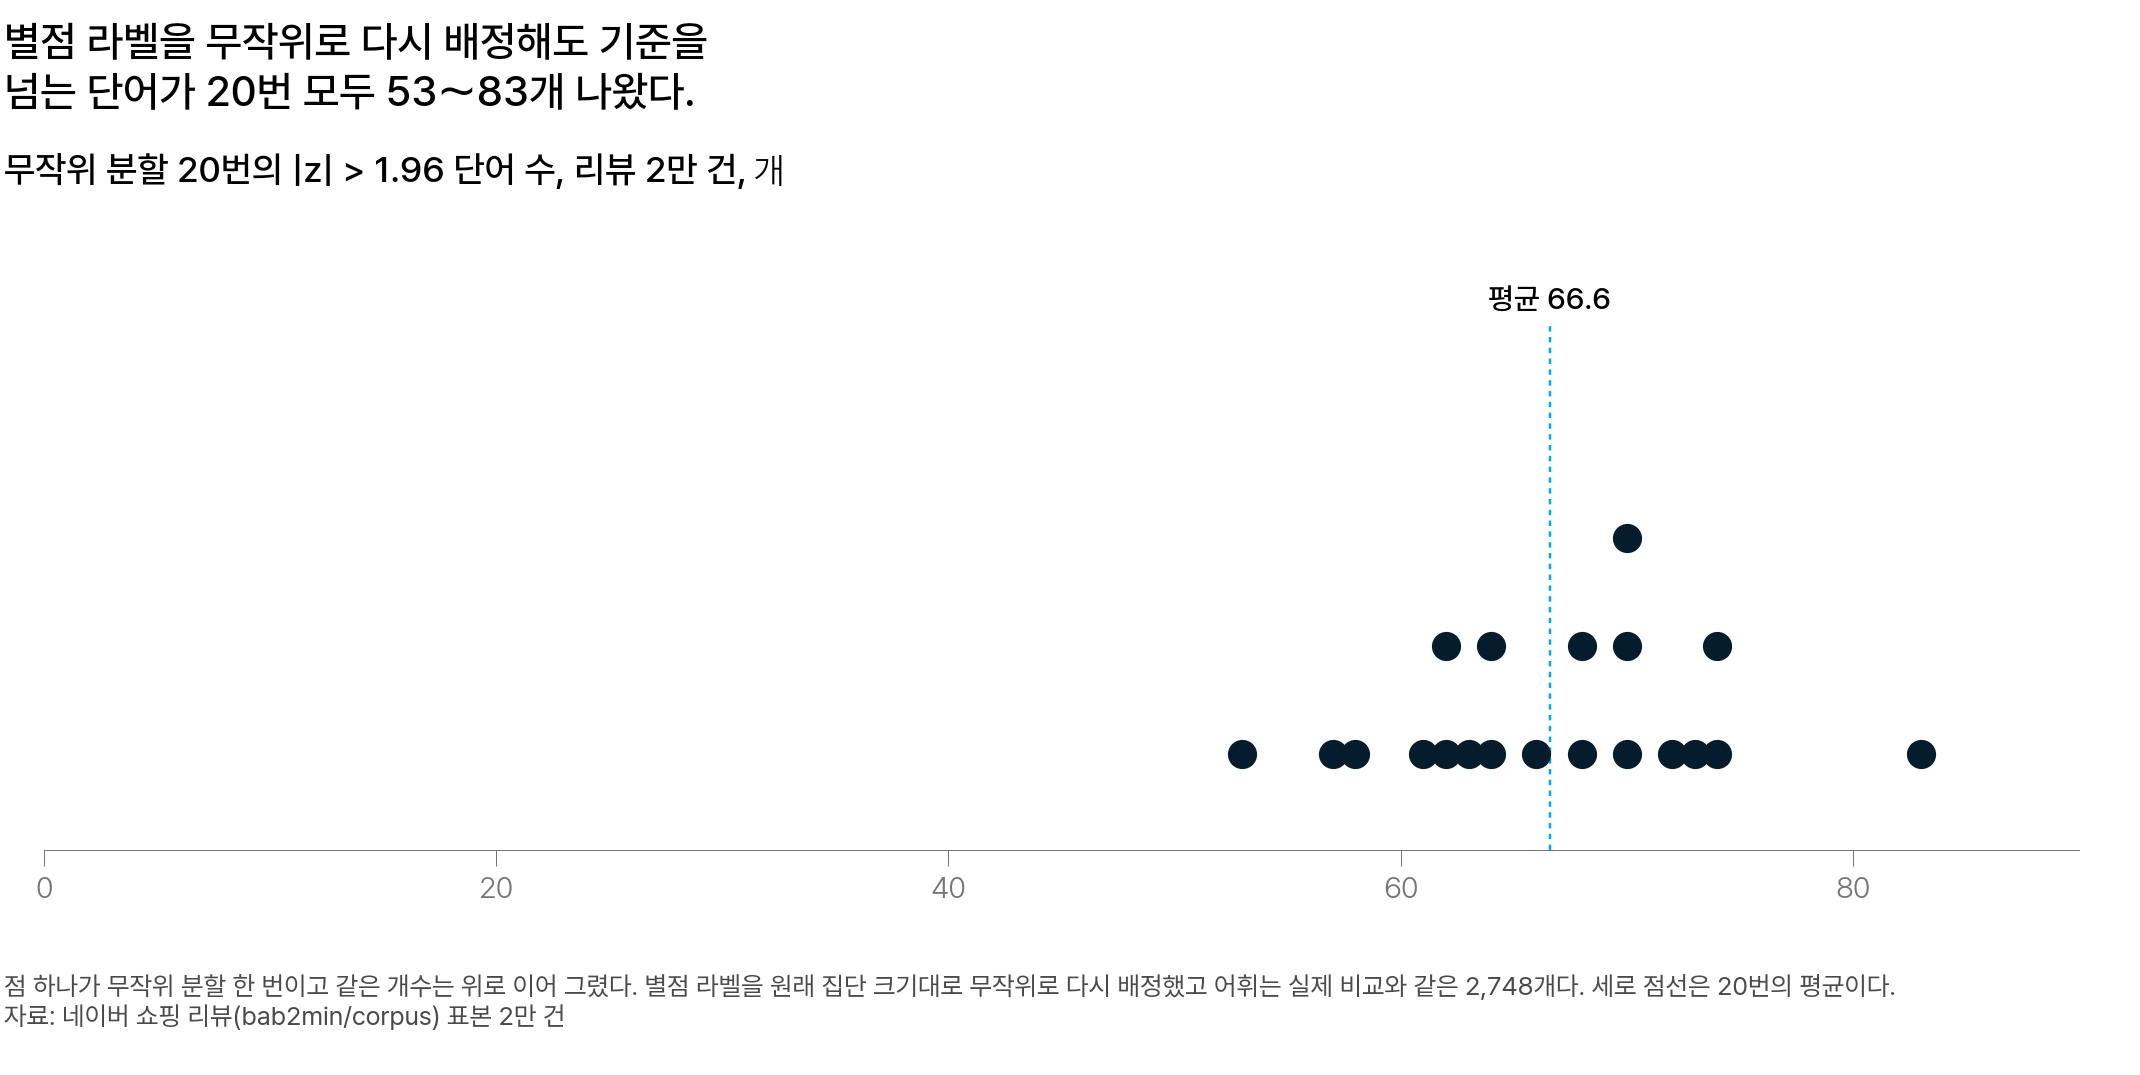

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 별점 라벨을 다시 배정한 비교 한 번에서 |z| 가 1.96 을 넘은 단어 수다(리뷰 2만 건). 점 하나가 배정 한 번이고, 하늘색 점선이 20번의 평균이다</em></p>

**762개 가운데 몇 개쯤이 우연일까요?**

정확한 개수는 알 수 없습니다. 차이가 없을 때 기준을 넘는 개수와 비교할 수 있을 뿐입니다.

| 비교 | 어휘 | $\lvert z \rvert > 1.96$ 인 단어 |
|---|---:|---:|
| 별점 1·2점 대 4·5점(실제 비교) | 2,748개 | 762개 |
| 별점 라벨을 다시 배정한 비교(20번 평균) | 2,748개 | 66.6개 |

차이가 없을 때도 평균 66.6개가 기준을 넘습니다. 762개는 그 11배쯤이라, 762개 대부분이 우연만으로 나왔다고 보기는 어렵습니다. 다만 762개 가운데 몇 개가, 어느 단어가 우연인지는 이 비교로 알 수 없습니다.

5% 라면 2,748개 가운데 약 137개일 텐데 66.6개(2.4%)뿐입니다. 2,748개 가운데 2,075개가 문서 30건 미만인 드문 단어라, 한쪽에 몰려도 $|z|$ 가 1.96 보다 커지기 어렵기 때문입니다.

<details class="lms-extra"><summary>자세히 — 무작위 분할의 비율이 5% 보다 작은 이유</summary>

민원의 「수강」도 9건 대 0건이었는데 $z$ 는 2.00 이었습니다. 드문 단어는 문서가 모두 한쪽 집단에 들어가도 표준오차가 커서 $|z|$ 가 크지 않습니다. 그래서 차이가 없을 때 기준을 넘는 비율이 5% 보다 작게 나옵니다.

</details>

그래서 우연이 만들 수 있는 가장 큰 $|z|$ 를 구해, 그보다 큰 단어에서 특징 단어를 고릅니다.

### 우연만으로 나온 가장 큰 |z| [필수]

**차이가 없을 때 $|z|$ 는 어디까지 커지나요?**

리뷰 자료에서는 4.91 까지 커졌습니다. 라벨을 다시 배정한 20번에서 번마다 가장 큰 $|z|$ 를 구하면 2.82～4.91 이고, 그 최댓값 4.91 이 **우연만으로 나온 가장 큰 $|z|$** 입니다.

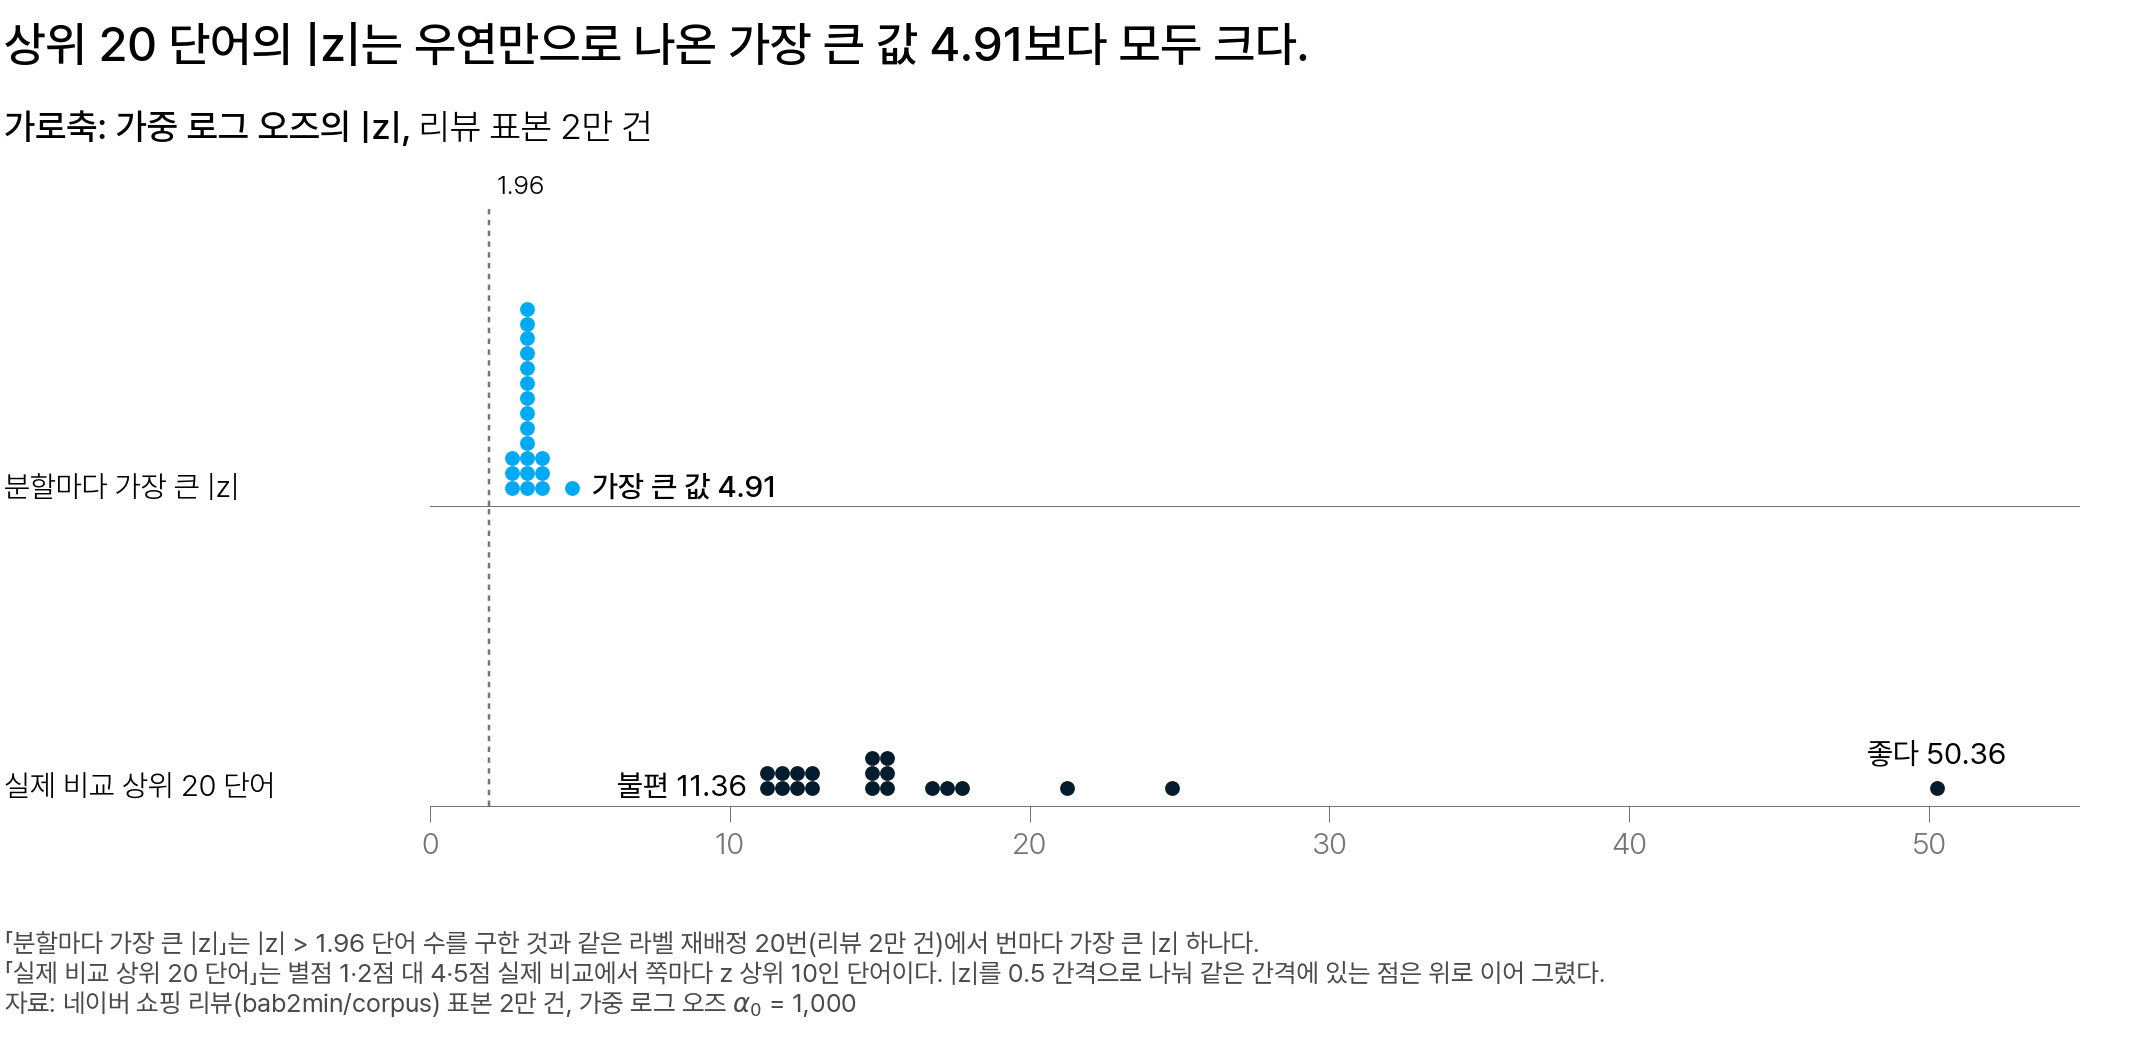

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 하늘색 점은 라벨을 다시 배정한 20번에서 번마다 가장 큰 |z|(2.82～4.91), 남색 점은 별점 비교 양쪽 상위 10 씩 20 단어의 |z|(11.36～50.36)다. 점선은 1.96 이다</em></p>

별점 비교 양쪽 상위 10 씩 20 단어는 $|z|$ 가 11.36～50.36 이라 모두 4.91 을 크게 넘습니다. 우연일 수 있는 단어는 $|z|$ 가 1.96～4.91 인 단어입니다.

1.96 은 단어 하나만 볼 때의 기준이라, 수천 개를 한꺼번에 보면 우연도 넘습니다. 무작위 분할 비교로 구한 두 수는 답하는 질문이 다릅니다.

| 질문 | 쓰는 값 | 이 자료의 답 |
|---|---|---|
| 차이가 없을 때도 1.96 을 넘는 단어는 몇 개인가 | 배정할 때마다 1.96 을 넘은 단어 수 | 평균 66.6개 |
| 어느 단어부터 우연이 아니라고 보나 | 우연만으로 나온 가장 큰 $\lvert z \rvert$ | 4.91 |

특징 단어는 4.91 을 넘는 단어 가운데 $|z|$ 가 큰 순서로 고릅니다. 실제 비교 762개 가운데 134개가 4.91 을 넘습니다.

<div class="lms-summary">

**정리**

- 단어가 많으면 진짜 차이가 없어도 우연만으로 $|z|$ 가 1.96 을 넘는 단어가 나옵니다.
- 별점 라벨을 다시 배정한 비교에서도 평균 66.6개가 기준을 넘었습니다. 762개는 그 11배쯤이라 대부분이 우연이라고 보기는 어렵지만, 어느 단어가 우연인지는 모릅니다.
- 특징 단어는 우연만으로 나온 가장 큰 $|z|$ 4.91 을 넘는 단어에서 고릅니다.

**할 일**

- 다른 자료를 비교할 때는 그 자료의 라벨을 다시 배정해 무작위 분할 비교를 다시 합니다

무작위 분할 비교는 우연이 만드는 차이의 크기를 그 자료로 직접 보여 줍니다.

</div>

> **[문제] 리뷰 표본 2만 건에서 별점 1·2점과 4·5점을 비교했습니다. |z| > 1.96 인 단어는 어휘 2,748개 가운데 762개(27.7%)였습니다. 별점 라벨을 무작위로 다시 배정한 비교도 20번 했습니다. 이 비교에서는 같은 어휘 2,748개 가운데 평균 66.6개(53～83개)였습니다. 이 두 수를 맞게 읽은 것은 무엇일까요?**
>
> 1. 762개 가운데 66.6개를 뺀 약 695개는 모두 별점과 관계가 확실한 단어이다
> 2. 라벨을 다시 배정한 비교에서 66.6개가 나왔으니 가중 로그 오즈 계산이 틀렸다
> 3. 차이가 없어야 할 비교에서도 수십 개가 나오므로, z 가 1.96 근처인 단어는 우연으로 들어왔을 수 있다

## 5. 구성 효과

민원마다 상품 · 서비스의 분류인 **품목**(예: 헬스장)이 있습니다. 20대 쪽 특징 단어는 20대가 그 단어를 더 쓴다는 뜻일까요, 그 단어가 자주 나오는 품목이 20대 민원에 많다는 뜻일까요?

### 구성 효과란 무엇인가 [필수]

**품목 구성만으로도 전체 비율 차이가 생기나요?**

생깁니다. 계산하기 쉬운 수로 봅니다. 「헬스장」이라는 단어는 헬스장 품목 민원에만 나오고, 그 품목 안에서는 두 연령대 모두 45% 가 쓴다고 합시다.

| 연령대 | 헬스장 품목 비중 | 품목 안 비율 | 전체 비율 |
|---|---:|---:|---:|
| 20대 | 10% | 45% | 10% × 45% = 4.5% |
| 60대 이상 | 0.5% | 45% | 0.5% × 45% = 0.225% |

품목 안에서는 같은데 전체로는 20배 차이가 납니다. 이처럼 집단의 구성 때문에 전체 차이가 생기거나 바뀌는 것을 **구성 효과(composition effect)** 라고 합니다. 통계적 검정과 인과추론 수업에서 본 **심슨의 역설**이 그 예입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/1/15/Simpson_paradox_kidney_stones.svg" alt="치료 건수(가로)와 성공 건수(세로)를 화살표로 그린 그림 — 작은 결석과 큰 결석 각각에서는 주황 A 의 기울기가 파랑 B 보다 가파르지만, 둘을 합친 화살표는 파랑 B 가 더 가파르다" width="480" height="400"/>
<p align="center"><em>▲ 신장 결석 치료 A(주황)와 B(파랑)의 치료 건수(가로)와 성공 건수(세로). 화살표의 기울기가 성공률이다 (출처: Wikimedia Commons, Cmglee, CC BY-SA 4.0)</em></p>

작은 결석과 큰 결석을 따로 보면 A 의 성공률이 높고, 둘을 합치면 B 가 높습니다. 성공률이 낮은 큰 결석이 A 로 치료한 환자에 더 많았기 때문입니다. 민원으로 옮기면 치료는 연령대, 결석 크기는 품목, 성공률은 그 단어를 쓴 민원의 비율입니다.

<details class="lms-extra"><summary>더 깊이 — 두 수치 사이의 관계에서 보는 심슨의 역설</summary>

비율이 아니라 두 수치 사이의 관계에서도 같은 일이 생깁니다. 아래 그림의 가로 · 세로는 아무 두 수치이고, 색이 숨은 집단입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/47/Simpson%27s_paradox_continuous.svg" alt="집단마다의 관계와 전체 관계가 반대인 점 여덟 개" width="390" height="260" />
<p align="center"><em>▲ 파랑 점과 빨강 점은 각각 오른쪽 위로 가는 선(실선)을 따르는데, 점 8개 전체의 선(검은 점선)은 오른쪽 아래로 간다. 숨은 집단은 점의 색이다 (출처: Wikimedia Commons, Public domain)</em></p>

</details>

**실제 민원의 품목 구성은 얼마나 다른가요?**

크게 다릅니다. 괄호 안은 그 연령대 민원 가운데 비율입니다.

| 품목 | 20대 | 60대 이상 |
|---|---:|---:|
| 헬스장 | 208건(9.56%) | 11건(0.45%) |
| 투자자문(컨설팅) | 20건(0.92%) | 88건(3.60%) |

헬스장 품목 비중은 앞의 쉬운 수(10% 대 0.5%)와 거의 같습니다. 그래서 20대 쪽 상위의 「헬스장」 · 「필라테스」는 품목 구성에서 나왔을 수 있습니다. 60대 이상 쪽의 「주식」 · 「투자」도 투자자문 품목이 많아서일 수 있습니다.

### 같은 품목 안의 비교 [필수]

품목 구성 때문인지는 같은 품목의 민원끼리 비교해 구분합니다. 이것이 **같은 품목 안의 비교**입니다. 품목 안에서도 20대가 더 쓰면, 그 차이는 품목 구성만으로 설명되지 않습니다.

두 연령대를 합친 민원 수가 많은 5개 품목에서 다시 계산합니다. 헬스장 · 이동전화서비스 · 기타미분류서비스 · 기타미분류물품 · 국외여행으로, 각 115～219건입니다. 합친 수가 많아도 한쪽은 적을 수 있습니다. 헬스장 품목의 60대 이상은 11건뿐입니다.

**「헬스장」 · 필라테스 · 학원은 품목 안에서도 20대가 더 쓰나요?**

아닙니다. 세 단어 모두 다섯 품목 가운데 헬스장 품목에서 $z$ 가 가장 커, 이 품목 안에서 문서 비율을 비교합니다.

| 단어 | 품목 안 20대(208건 중) | 품목 안 60대 이상(11건 중) | 품목 안 $z$ | 전체 $z$ |
|---|---:|---:|---:|---:|
| 헬스장 | 93건 44.7% | 5건 45.5% | 4.06 | 7.47 |
| 필라테스 | 26건 12.5% | 2건 18.2% | 1.83 | 4.36 |
| 학원 | 5건 2.4% | 0건 0.0% | 0.93 | 5.13 |

「헬스장」은 비율이 거의 같고(44.7% 대 45.5%), 필라테스는 60대 이상이 더 높습니다. 학원은 5건 대 0건이라 판단할 건수가 없습니다.

**비율이 같은데 「헬스장」의 $z$ 는 왜 4.06 인가요?**

60대 이상이 11건뿐이라 사전 문서 수가 그 비율을 크게 바꾸기 때문입니다. 사전 문서 수를 더하면 건수가 적은 쪽 비율일수록 기본값에 가까워집니다. 기본값은 이 품목 단어들이 나온 문서 수를 모두 더한 968 가운데 「헬스장」 98건, 약 10% 입니다.

| 집단 | 실제 문서 비율 | 사전 문서 수를 더한 비율 |
|---|---:|---:|
| 20대 | 93 ÷ 208 = 44.7% | 16.08% |
| 60대 이상 | 5 ÷ 11 = 45.5% | 10.51% |

두 집단 모두 1,000 보다 적어 둘 다 기본값 10% 에 가까워지는데, 11건인 쪽이 더 가까워집니다. 60대 이상은 45.5% 가 10.51% 가 되고, 20대는 44.7% 가 16.08% 가 됩니다. 그래서 거의 같던 비율이 16.08% 대 10.51% 로 달라져 $z$ 가 4.06 이 됩니다.

이처럼 두 집단 크기가 크게 다르면 기본값에 가까워지는 정도가 달라 $z$ 가 실제 비율 차이를 따르지 않습니다. 그래서 품목 안 비교에서는 문서 비율을 먼저 보고 $z$ 는 참고로만 씁니다.

<details class="lms-extra"><summary>자세히 — 문서 비율이 거의 같은데 z 가 4.06 이 되는 계산</summary>

아래에서 $a$ 는 20대, $b$ 는 60대 이상입니다. 「헬스장」에 더하는 사전 문서 수 $\alpha_w$ 는 두 집단에 같습니다. α₀ 1,000 에, 이 품목 단어 43개마다 쓴 문서 수를 모두 더한 968 가운데 「헬스장」 98건(93 + 5)의 비율을 곱합니다.

$$
\alpha_w = 1{,}000 \times \frac{98}{968} = 101.24
$$

사전 문서 수를 더한 비율 $\tilde p$ 는 분자에 $\alpha_w$ 를, 분모에 α₀ 1,000 을 더해 나눕니다.

$$
\begin{aligned}
\text{20대:}\quad & \tilde p_a = \frac{93 + 101.24}{208 + 1{,}000} = \frac{194.24}{1{,}208} = 16.08\% \\
\text{60대 이상:}\quad & \tilde p_b = \frac{5 + 101.24}{11 + 1{,}000} = \frac{106.24}{1{,}011} = 10.51\%
\end{aligned}
$$

실제 비율이 차지하는 가중치는 $n/(n + \alpha_0)$ 입니다. 20대는 208 ÷ 1,208 = 17.22%, 60대 이상은 11 ÷ 1,011 = 1.09% 라, 60대 이상의 $\tilde p$ 는 $\alpha_w/\alpha_0$(10.12%) 에 가깝습니다.

두 값으로 가중 로그 오즈의 $z$ 를 구합니다. 로그 안의 분모는 사전 문서 수를 더한 뒤 「헬스장」을 쓰지 않은 문서 수입니다.

$$
\begin{aligned}
\text{20대 로그 오즈:}\quad & \ln\frac{194.24}{1{,}013.76} = -1.6523 \\
\text{60대 이상 로그 오즈:}\quad & \ln\frac{106.24}{904.76} = -2.1420 \\
\text{두 로그 오즈를 뺀다:}\quad & \hat\delta_w = -1.6523 - (-2.1420) = 0.4897 \\
\text{두 역수를 더한다:}\quad & \hat\sigma^2_w = \frac{1}{194.24} + \frac{1}{106.24} = 0.014561 \\
\text{표준오차로 나눈다:}\quad & z_w = \frac{0.4897}{\sqrt{0.014561}} = \frac{0.4897}{0.1207} = 4.06
\end{aligned}
$$

필라테스의 $z$ 가 양수(1.83)인 것도 같은 이유입니다.

</details>

**그러면 품목 안 결과로 무엇을 말할 수 있나요?**

그 단어를 쓴 민원이 비교한 다섯 품목 안에 얼마나 있는지로 정합니다.

- 「헬스장」 · 필라테스: 쓴 민원 대부분이 다섯 품목 안입니다(「헬스장」 107건 가운데 98건, 필라테스 37건 가운데 28건). 그 안에서 20대 비율이 높지 않아 품목 구성의 차이일 수 있습니다.
- 학원: 51건 가운데 46건이 다섯 품목 밖이라 이 비교로는 판단할 수 없습니다.

품목 안에서 기준을 넘지 않았다고 차이가 없다는 뜻은 아닙니다. 60대 이상은 11건이라 1건만 달라져도 비율이 약 9%p 바뀌어, 같다고까지는 말할 수 없습니다. 그래서 「차이일 수 있다」까지만 씁니다.

<div class="lms-summary">

**정리**

- 두 집단의 품목 구성이 다르면, 품목 안에서는 같아도 전체 비율이 다르게 나옵니다(구성 효과).
- 「헬스장」 · 필라테스 · 학원은 같은 품목 안에서 20대가 더 쓴다고 확인되지 않았습니다.

**할 일**

- 두 집단의 품목 비율을 먼저 보고, 같은 품목 안에서는 건수와 문서 비율을 본 뒤 $z$ 를 봅니다

두 집단 크기가 크게 다르고 사전 문서 수보다 적으면 $z$ 는 실제 비율 차이를 따르지 않습니다.

</div>

> **[문제] 20대 쪽 특징 단어 「필라테스」가 두 연령대 문서가 많은 품목 5개 안의 비교에서 모두 |z| > 1.96 을 넘지 않았다. 그러므로 20대와 60대 이상은 필라테스 민원을 같은 비율로 낸다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 6. 정리와 팀 라운드

별점 낮은 리뷰와 20대 민원의 특징 단어를 각각 어디까지 말할 수 있을까요?

### 특징 단어를 쓰기 전에 확인할 세 가지 [필수]

**특징 단어는 어떤 순서로 확인하나요?**

TF-IDF 는 문서 하나 안의 값이라 집단 비교에 쓰지 않습니다. 아래 세 가지를 차례로 확인합니다.

| 확인 | 알 수 있는 것 |
|---|---|
| ① 가중 로그 오즈 | 어느 집단이 더 쓰는지, 그 차이가 표준오차의 몇 배인지($z$) |
| ② 무작위 분할 비교 | 우연만으로 기준을 넘는 단어 수와 가장 큰 $\lvert z \rvert$ |
| ③ 같은 품목 안의 비교 | 품목 구성 때문에 생긴 차이인지 |

별점 리뷰의 특징 단어는 ①과 ②를 통과했습니다. 리뷰에는 품목 정보가 없어 ③은 하지 못했습니다.

**20대 쪽 1위 「환불」은 세 가지를 통과하나요?**

| 확인 | 20대 쪽 「환불」의 결과 |
|---|---|
| ① 가중 로그 오즈 | $z$ 14.12 로 1위. 20대 612/2,175건(28.14%) · 60대 이상 265/2,446건(10.83%) |
| ② 무작위 분할 비교 | 민원으로는 아직 하지 않음. 리뷰의 4.91 은 어휘 수와 문서 수가 달라 빌려 쓰지 않음. 세 단어의 z(4.36 · 5.13 · 7.47)는 4.91 의 아래위에 걸쳐 있어, 민원에서 다시 구한 값에 따라 결론이 달라질 수 있음 |
| ③ 같은 품목 안의 비교 | 다섯 품목 가운데 헬스장 품목에서만 1.96 을 넘음($z$ 4.11). 그 품목 안 비율은 20대 100/208건(48.1%) · 60대 이상 7/11건(63.6%) |

③ 의 $z$ 4.11 은 60대 이상 비율이 더 높은데도 20대 쪽으로 나왔습니다. 「헬스장」의 4.06 처럼 60대 이상이 11건뿐이라 생긴 값입니다. 또 「환불」을 쓴 민원 877건 가운데 다섯 품목 안은 169건(19.3%)뿐이라, 나머지는 품목 구성 때문인지 확인하지 못했습니다. 원문을 보면 「환불」은 품목마다 다른 일에 쓰였습니다.

> 「헬스장 pt 환불 문의」(헬스장 품목)
>
> 「국내여행 취소 환불 문의」(국외여행 품목, 품목명은 원자료 그대로)

PT 환불과 여행 취소 환불은 다른 일이라, 「환불」 하나의 $z$ 로 묶어 해석하지 않습니다.

**확인한 결과는 어떤 문장으로 정리하나요?**

통과한 확인만큼만 말합니다. 민원 수는 불만의 크기가 아니라 접수 건수라, 「불만이 많다」 대신 무엇이 몇 건인지를 씁니다.

| 단어 | 확인 결과 | 쓸 수 있는 문장 |
|---|---|---|
| 민원의 모든 단어 | ② 를 아직 하지 않았다 | 「z 가 기준을 넘었다」까지(몇 개가 우연인지는 모른다) |
| (확인한 네 단어 가운데는 없음) | ③ 에서도 넘고, 품목 안 비율도 20대가 높다 | 「같은 품목 안에서도 20대가 이 단어를 더 쓴다고 볼 수 있다」 |
| 「헬스장」 · 필라테스 | 품목 안 비율이 20대가 높지 않고, 쓴 민원 대부분이 다섯 품목 안 | 「품목 구성의 차이일 수 있다」 |
| 학원 · 「환불」 | 쓴 민원 대부분이 다섯 품목 밖 | 「전체 문서 비율에 차이가 있지만, 품목 구성 때문인지는 이 비교로 판단할 수 없다」 |

그래서 「환불」은 이렇게 씁니다. 「「환불」은 20대 민원의 28%, 60대 이상 민원의 11% 에 나온다. 품목 구성 때문인지와 우연인지는 아직 확인하지 못했다.」

<details class="lms-extra"><summary>더 깊이 — 우연만으로 나온 가장 큰 |z| 가 비교마다 다른 이유</summary>

<img src="https://upload.wikimedia.org/wikipedia/commons/c/c1/Galton_box.jpg" alt="골턴 상자 아래에 모인 구슬" width="320" height="480" />
<p align="center"><em>▲ 골턴 상자. 구슬은 못을 지날 때마다 왼쪽이나 오른쪽으로 무작위로 떨어진다. 원인이 없어도 양 끝까지 떨어지는 구슬이 있다 (출처: Wikimedia Commons, CC BY-SA 4.0)</em></p>

무작위 분할에서는 단어 하나가 구슬 하나이고, 그 단어를 쓴 문서 수가 구슬이 지나는 층 수입니다.

- 단어가 많을수록 우연만으로 $|z|$ 가 큰 단어가 나올 기회가 늘어, 가장 큰 값도 커지기 쉽습니다.
- 쓴 문서가 적은 단어는 문서가 모두 한쪽 집단에 들어가도 $|z|$ 가 작습니다.

리뷰의 4.91 은 어휘 2,748개, 9,947건 대 10,053건에서 구한 값입니다. 민원 비교는 어휘 703개, 2,175건 대 2,446건이라 이 값을 빌려 쓰지 않고, 민원의 연령대 라벨을 무작위로 다시 배정해 다시 구합니다.

</details>

<div class="lms-summary">

**정리**

- 특징 단어는 $z$ 로 고르고, 우연과 품목 구성을 확인한 만큼만 말합니다.
- 별점 낮은 리뷰에는 「없다 · 반품 · 불편 · 떨어지다」가, 높은 리뷰에는 「좋다 · 빠르다 · 만족」이 더 자주 나옵니다.

**할 일**

- 특징 단어 후보는 같은 자료의 무작위 분할 비교와 같은 품목 안의 비교를 거친 뒤, 원문을 읽어 쓰인 뜻을 확인합니다

20대 민원의 1위 「환불」은 품목 구성 때문인지와 우연인지 아직 판단할 수 없습니다.

</div>

### 팀 라운드: 20대 특징 단어를 마케팅팀에 전달할 때 [필수]

**아래 질문의 답은 수업에서 팀이 함께 정합니다.** 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 20대 특징 단어를 마케팅팀에 전달할 때**
>
> 마케팅팀이 20대 민원에서 두드러지는 단어를 물어, 팀이 보낼 내용을 정해야 합니다. 20대와 60대 이상의 민원 제목(표본 2만 건)을 가중 로그 오즈로 비교하니 20대 쪽 상위 10 에 헬스장 · 학원 · 필라테스가 있었습니다. 동료는 이 세 단어를 들어 「20대는 운동 · 교육 시설에 불만이 많다」고 보내자고 합니다.
> 
> - **전체 비교의 z** 헬스장 7.47, 학원 5.13, 필라테스 4.36
> - **우연만으로 나온 가장 큰 |z|** 4.91(별점 리뷰 2만 건의 라벨을 무작위로 다시 배정한 비교, 민원으로는 아직 구하지 않음)
> - **헬스장 품목이 연령대 민원에서 차지하는 비율** 표본 2만 건 20대 9.56% · 60대 이상 0.45%(11건), 민원 50만 건 20대 9.27% · 60대 이상 0.76%(464건)
> - **헬스장 품목 안의 「헬스장」** z 4.06, 문서 비율 20대 44.7% · 60대 이상 45.5%
> 
> 팀 안에서 의견이 3가지로 나뉘었습니다.
> 
> - **관점 A: 그대로 보낸다.** 세 단어의 전체 비교 z 는 우연만으로 나온 가장 큰 |z| 와 비슷하거나 더 크다. 우연으로 오른 단어가 아니니 20대 특징 단어로 보내도 된다.
> - **관점 B: 같은 품목 안에서도 기준을 넘고, 문서 비율도 20대가 높은 단어만 보낸다.** 이 기준이면 세 단어는 모두 빠진다. 상위 10 의 나머지 단어도 같은 기준으로 확인해 통과한 것만 보낸다.
> - **관점 C: 단어 대신 품목 구성을 보낸다.** 세 단어 대신 두 연령대 민원에서 헬스장 품목이 차지하는 비율과 원문 인용을 보낸다. 민원 수는 접수 건수라 「불만이 많다」는 쓰지 않는다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.